In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')



from xgboost import XGBRegressor

from sklearn.metrics import root_mean_squared_log_error
from xgboost import XGBRegressor



/kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/train.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/test.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv


# 01. Dataset Loading & Structure Analysis

In this section, we will load all competition datasets and explore their basic structure, dimensions, and data types.

In [2]:
import pandas as pd
import numpy as np

DATA_DIR = "/kaggle/input/competitions/store-sales-time-series-forecasting/"

# Load datasets
train = pd.read_csv(DATA_DIR + "train.csv")
test = pd.read_csv(DATA_DIR + "test.csv")
stores = pd.read_csv(DATA_DIR + "stores.csv")
oil = pd.read_csv(DATA_DIR + "oil.csv")
holidays = pd.read_csv(DATA_DIR + "holidays_events.csv")
transactions = pd.read_csv(DATA_DIR + "transactions.csv")
sample_submission = pd.read_csv(DATA_DIR + "sample_submission.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


## 2. Dataset Overview

In this step, we examined the dimensions of all provided datasets to understand their sizes and get an initial overview of the available data.

In [3]:
datasets = {
    "Train": train,
    "Test" : test,
    "Stores" : stores,
    "Oil" : oil,
    "Holidays" : holidays,
    "Transactions" : transactions,
    "Sample Submission": sample_submission
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Train: (3000888, 6)
Test: (28512, 5)
Stores: (54, 5)
Oil: (1218, 2)
Holidays: (350, 6)
Transactions: (83488, 3)
Sample Submission: (28512, 2)


## 3. Columns and Data Types

In this step, we inspected the columns and data types of each dataset to understand the available features and identify potential preprocessing requirements.

In [4]:
for name, df in datasets.items():

    print(f"\n{'='*50}")
    print(f"Dataset: {name}")
    print(f"{'='*50}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)


Dataset: Train

Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Data Types:
id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

Dataset: Test

Columns:
['id', 'date', 'store_nbr', 'family', 'onpromotion']

Data Types:
id              int64
date           object
store_nbr       int64
family         object
onpromotion     int64
dtype: object

Dataset: Stores

Columns:
['store_nbr', 'city', 'state', 'type', 'cluster']

Data Types:
store_nbr     int64
city         object
state        object
type         object
cluster       int64
dtype: object

Dataset: Oil

Columns:
['date', 'dcoilwtico']

Data Types:
date           object
dcoilwtico    float64
dtype: object

Dataset: Holidays

Columns:
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

Data Types:
date           object
type           object
locale         object
locale_name    object
descript

## 4. Unique Values Analysis

In this step, we examined the number of unique values in selected columns to identify potential keys and better understand the structure of each dataset.

In [5]:
key_candidates = {
    "Train": {
        "id": train,
        "store_nbr": train,
        "family": train,
        "date": train
    },
    "Stores": {
        "store_nbr": stores
    },
    "Oil": {
        "date": oil
    },
    "Holidays": {
        "date": holidays
    },
    "Transactions": {
        "store_nbr": transactions,
        "date": transactions
    }
}

for dataset_name, columns in key_candidates.items():

    print(f"\n{'='*40}")
    print(dataset_name)
    print(f"{'='*40}")

    for column, df in columns.items():
        print(
            f"{column}: "
            f"{df[column].nunique()} unique values "
            f"out of {len(df)} rows"
        )


Train
id: 3000888 unique values out of 3000888 rows
store_nbr: 54 unique values out of 3000888 rows
family: 33 unique values out of 3000888 rows
date: 1684 unique values out of 3000888 rows

Stores
store_nbr: 54 unique values out of 54 rows

Oil
date: 1218 unique values out of 1218 rows

Holidays
date: 312 unique values out of 350 rows

Transactions
store_nbr: 54 unique values out of 83488 rows
date: 1682 unique values out of 83488 rows


## 5. Missing Values Analysis

In this step, we investigated missing values across all datasets to identify incomplete data and determine which features may require further attention during preprocessing.

In [6]:
for name, df in datasets.items():

    print("\n" + "=" * 40)
    print(f"Missing Values - {name}")
    print("=" * 40)

    missing = df.isnull().sum()

    missing_percentage = (missing / len(df)) * 100

    missing_report = pd.DataFrame({
        "Missing Values": missing,
        "Percentage (%)": missing_percentage
    })

    print(missing_report)


Missing Values - Train
             Missing Values  Percentage (%)
id                        0             0.0
date                      0             0.0
store_nbr                 0             0.0
family                    0             0.0
sales                     0             0.0
onpromotion               0             0.0

Missing Values - Test
             Missing Values  Percentage (%)
id                        0             0.0
date                      0             0.0
store_nbr                 0             0.0
family                    0             0.0
onpromotion               0             0.0

Missing Values - Stores
           Missing Values  Percentage (%)
store_nbr               0             0.0
city                    0             0.0
state                   0             0.0
type                    0             0.0
cluster                 0             0.0

Missing Values - Oil
            Missing Values  Percentage (%)
date                     0        0.000

## 6. Duplicate Analysis

In this step, we checked all datasets for completely duplicated rows to identify potential data quality issues and ensure the reliability of the data.

In [7]:
for name, df in datasets.items():

    print(f"\n{'='*40}")
    print(f"Duplicate Analysis - {name}")
    print(f"{'='*40}")

    duplicates = df.duplicated().sum()

    print(f"Duplicate Rows: {duplicates}")
    print(f"Duplicate Percentage: {(duplicates / len(df)) * 100:.4f}%")


Duplicate Analysis - Train
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Test
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Stores
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Oil
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Holidays
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Transactions
Duplicate Rows: 0
Duplicate Percentage: 0.0000%

Duplicate Analysis - Sample Submission
Duplicate Rows: 0
Duplicate Percentage: 0.0000%


## 7. Date Range Analysis

In this step, we examined the date ranges of the main datasets to understand their temporal coverage and identify potential limitations when building forecasting features.


In [8]:
date_columns = {
    "Train": train,
    "Test": test,
    "Oil": oil,
    "Holidays": holidays,
    "Transactions": transactions
}

for name, df in date_columns.items():
    df["date"] = pd.to_datetime(df["date"])

    print(f"\n{'='*40}")
    print(f"Date Range - {name}")
    print(f"{'='*40}")

    print("Start Date:", df["date"].min())
    print("End Date:", df["date"].max())
    print("Unique Dates:", df["date"].nunique())


Date Range - Train
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00
Unique Dates: 1684

Date Range - Test
Start Date: 2017-08-16 00:00:00
End Date: 2017-08-31 00:00:00
Unique Dates: 16

Date Range - Oil
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-31 00:00:00
Unique Dates: 1218

Date Range - Holidays
Start Date: 2012-03-02 00:00:00
End Date: 2017-12-26 00:00:00
Unique Dates: 312

Date Range - Transactions
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00
Unique Dates: 1682



### Date Range Summary

| Dataset | Start Date | End Date | Unique Dates |
|---|---|---|---:|
| Train | 2013-01-01 | 2017-08-15 | 1,684 |
| Test | 2017-08-16 | 2017-08-31 | 16 |
| Oil | 2013-01-01 | 2017-08-31 | 1,218 |
| Holidays | 2012-03-02 | 2017-12-26 | 312 |
| Transactions | 2013-01-01 | 2017-08-15 | 1,682 |

### Key Findings

1. **Training Period:** The training dataset covers approximately 4 years and 7 months, from January 1, 2013, to August 15, 2017.

2. **Testing Period:** The test dataset covers 16 days, from August 16 to August 31, 2017, immediately following the training period.

3. **Oil Data:** The oil dataset extends through the entire test period, making it a potentially useful feature for forecasting.

4. **Holidays Data:** The holidays dataset covers a wider period than both training and testing, allowing us to extract holiday-related features for the test period.

5. **Transactions Data:** The transactions dataset ends on August 15, 2017. Therefore, actual transaction values are unavailable for the test period and cannot be directly used as future inputs.

6. **Date Coverage:** The transactions dataset contains 1,682 unique dates, compared with 1,684 unique dates in the training dataset. The missing dates require further investigation.

### Important Considerations

- Investigate the missing dates in the transactions dataset.
- Handle missing oil prices carefully before feature engineering.
- Avoid using unavailable future information when constructing features.
- Consider extracting calendar and holiday-related features.

### Conclusion

The datasets provide sufficient historical coverage for time series forecasting. However, their different date ranges and availability must be considered carefully during feature engineering and model development.

## 8. Target Analysis

In this step, we analyzed the target variable (sales) to understand its distribution, identify unusual values, and gain insights into the sales patterns before building forecasting models.

In [9]:
print("Target Statistics:")
display(train["sales"].describe())

print("\nZero Sales:")
print((train["sales"] == 0).sum())

print("\nNegative Sales:")
print((train["sales"] < 0).sum())

print("\nPositive Sales:")
print((train["sales"] > 0).sum())

Target Statistics:


count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64


Zero Sales:
939130

Negative Sales:
0

Positive Sales:
2061758


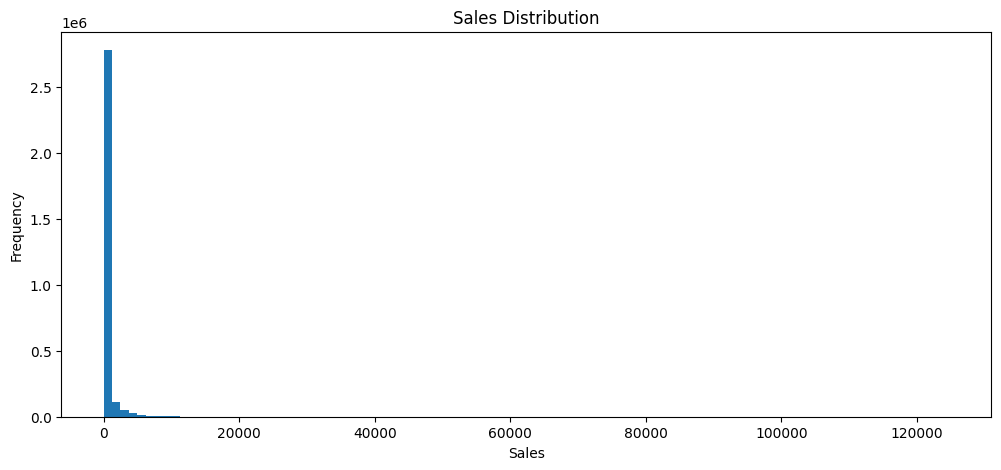

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(train["sales"], bins=100)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

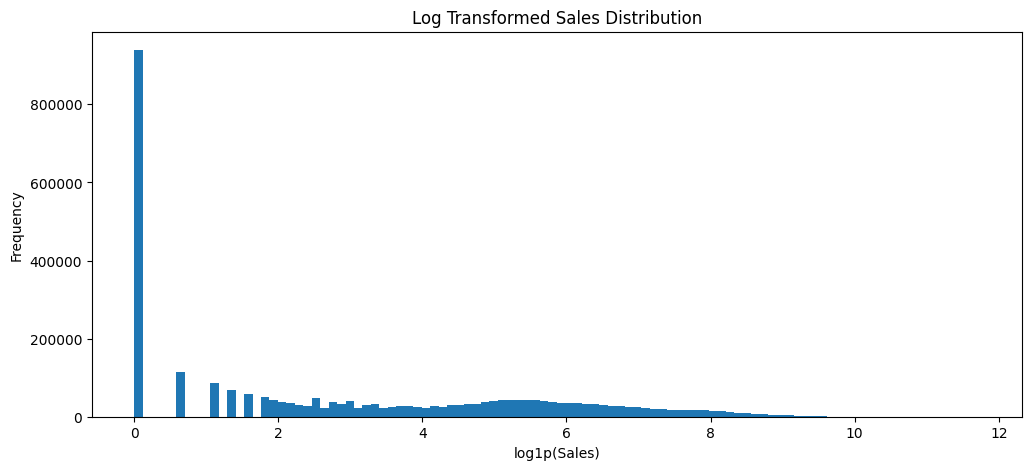

In [11]:
plt.figure(figsize=(12, 5))

plt.hist(np.log1p(train["sales"]), bins=100)

plt.title("Log Transformed Sales Distribution")
plt.xlabel("log1p(Sales)")
plt.ylabel("Frequency")

plt.show()

### Key Findings

1. **Zero Sales:** Approximately 31.29% of the training records have zero sales, indicating that zero values are a significant part of the dataset.

2. **Right-Skewed Distribution:** The original sales distribution is highly right-skewed, with most values concentrated near zero and a small number of extremely high sales values.

3. **Mean vs. Median:** The mean (357.78) is much higher than the median (11), suggesting that high sales values significantly affect the average.

4. **High Variability:** The standard deviation (1,101.99) is considerably larger than the mean, indicating substantial variation in sales across stores, product families, and dates.

5. **No Negative Values:** No negative sales values were found in the training dataset.

6. **Log Transformation:** Applying `log1p` makes the distribution easier to visualize by compressing large values while preserving zero values. However, the transformed distribution is still not normally distributed.

### Conclusion

The target variable has a highly skewed distribution, a substantial proportion of zero values, and considerable variability. These characteristics should be considered during feature engineering, model selection, and evaluation.

### **8.2 Sales Analysis by Product Family**

In this step, we analyzed sales across different product families to identify differences in sales patterns, average demand, and the proportion of zero-sales records.

In [12]:
family_stats = train.groupby("family").agg(
    Total_Sales=("sales", "sum"),
    Mean_Sales=("sales", "mean"),
    Median_Sales=("sales", "median"),
    Zero_Sales_Pct=("sales", lambda x: (x == 0).mean() * 100)
)

family_stats = family_stats.sort_values(
    by="Mean_Sales",
    ascending=False
)

display(family_stats)

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct
family,,,,
GROCERY I,3.434627e+08,3776.972100,3185.0000,8.062813
BEVERAGES,2.169545e+08,2385.793151,1784.0000,8.061714
PRODUCE,1.227047e+08,1349.352123,398.2905,28.355107
CLEANING,9.752129e+07,1072.416744,938.0000,8.061714
DAIRY,6.448771e+07,709.154889,520.0000,8.061714
BREAD/BAKERY,4.213395e+07,463.336254,401.0000,8.060614
POULTRY,3.187600e+07,350.532292,205.7430,8.076010
MEATS,3.108647e+07,341.849965,224.9365,8.061714
PERSONAL CARE,2.459205e+07,270.432513,222.0000,8.065013


### Key Findings

1. **Sales Differences:** Sales vary significantly across product families. GROCERY I has the highest average sales (3,776.97), while BOOKS has the lowest (0.07).

2. **High-Sales Families:** GROCERY I, BEVERAGES, PRODUCE, CLEANING, and DAIRY are among the highest-performing product families in terms of total and average sales.

3. **Low-Sales Families:** BOOKS, BABY CARE, and HOME APPLIANCES have very low average sales compared to other product families.

4. **Zero Sales:** The percentage of zero-sales records varies considerably across families. BOOKS has the highest percentage (96.96%), followed by BABY CARE (94.13%).

5. **Mean vs. Median:** For most product families, the mean is higher than the median, indicating right-skewed sales distributions.

6. **Different Sales Patterns:** The significant differences between product families suggest that sales behavior is not uniform across all categories.

7. **Potential Historical Effects:** Some product families have similar zero-sales percentages, around 8.06%, while others have substantially higher percentages. This pattern requires further investigation.

### Conclusion

Product families exhibit substantially different sales behaviors. These differences should be considered during feature engineering and model development. Further investigation is needed to understand the reasons behind the high proportion of zero-sales records in certain families.

### **8.3 Sales Analysis by Store**

In this step, we analyzed sales across different stores to identify differences in sales performance and understand how sales are distributed among store locations.

In [13]:
store_stats = train.groupby("store_nbr").agg(
    Total_Sales=("sales", "sum"),
    Mean_Sales=("sales", "mean"),
    Median_Sales=("sales", "median"),
    Zero_Sales_Pct=("sales", lambda x: (x == 0).mean() * 100)
)

store_stats = store_stats.sort_values(
    by="Mean_Sales",
    ascending=False
)

display(store_stats)

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct
store_nbr,,,,
44,6.208755e+07,1117.245254,75.0000,17.947887
45,5.449801e+07,980.673908,62.0000,19.358670
47,5.094831e+07,916.798209,51.0000,18.953790
3,5.048191e+07,908.405495,64.0000,18.140430
49,4.342010e+07,781.330450,48.0000,19.347873
46,4.189606e+07,753.905962,36.0000,19.320881
48,3.593313e+07,646.604950,30.0000,21.321889
51,3.291149e+07,592.231511,27.0000,20.121644
8,3.049429e+07,548.734739,39.0000,19.930900


### Key Findings

1. **Sales Differences:** Sales vary significantly across stores. Store 44 has the highest average sales (1,117.25), while Store 52 has the lowest (48.52).

2. **High-Performing Stores:** Stores 44, 45, 47, and 3 have the highest average sales among all stores.

3. **Low-Sales Stores:** Stores 52, 22, 42, and 21 have relatively low average sales compared to other stores.

4. **Zero Sales:** The percentage of zero-sales records varies considerably across stores. Store 52 has the highest percentage (93.54%), followed by Store 22 (68.55%).

5. **Median Sales:** Several stores have a median sales value of zero, indicating that at least half of their records have zero sales.

6. **Potential Store Effects:** Differences in store location, type, and cluster may help explain variations in sales performance.

### Conclusion

Sales behavior differs substantially across stores. Store-related information may provide useful features for forecasting. Stores with unusually high zero-sales percentages require further investigation before making assumptions about their sales patterns.

### **8.4 Store Metadata Analysis**

In this step, we combined store-level sales statistics with store metadata to investigate how store characteristics, including location, type, and cluster, relate to sales performance.

In [14]:
store_analysis = store_stats.merge(
    stores,
    on="store_nbr",
    how="left"
)

display(
    store_analysis.sort_values(
        by="Mean_Sales",
        ascending=False
    )
)

,store_nbr,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct,city,state,type,cluster
0,44,6.208755e+07,1117.245254,75.0000,17.947887,Quito,Pichincha,A,5
1,45,5.449801e+07,980.673908,62.0000,19.358670,Quito,Pichincha,A,11
2,47,5.094831e+07,916.798209,51.0000,18.953790,Quito,Pichincha,A,14
3,3,5.048191e+07,908.405495,64.0000,18.140430,Quito,Pichincha,D,8
4,49,4.342010e+07,781.330450,48.0000,19.347873,Quito,Pichincha,A,11
5,46,4.189606e+07,753.905962,36.0000,19.320881,Quito,Pichincha,A,14
6,48,3.593313e+07,646.604950,30.0000,21.321889,Quito,Pichincha,A,14
7,51,3.291149e+07,592.231511,27.0000,20.121644,Guayaquil,Guayas,A,17
8,8,3.049429e+07,548.734739,39.0000,19.930900,Quito,Pichincha,D,8
9,50,2.865302e+07,515.601753,32.0000,20.652487,Ambato,Tungurahua,A,14


### Key Findings

1. **Store Locations:** The highest-performing stores are concentrated in Quito, particularly stores 44, 45, 47, and 3.

2. **Store Types:** High-sales stores belong to different store types, indicating that store type alone may not explain sales performance.

3. **Store Clusters:** Stores with similar sales performance may belong to different clusters, suggesting that cluster information requires further investigation.

4. **Geographical Differences:** Low-performing stores are located in different cities, including Manta, Puyo, and Cuenca.

5. **Store Characteristics:** The merged dataset provides additional features such as city, state, store type, and cluster that may help explain differences in sales.

### Conclusion

Store metadata provides potentially useful information for understanding sales variations. However, the observed patterns are preliminary and require further analysis before drawing conclusions about the relationship between store characteristics and sales.

### **8.5 Sales Analysis by Store Type**

In this step, we grouped stores by their types to investigate differences in sales performance and examine whether store classification is associated with sales patterns.

In [15]:
store_type_stats = train.merge(
    stores[["store_nbr", "type"]],
    on="store_nbr",
    how="left"
).groupby("type").agg(
    Total_Sales=("sales", "sum"),
    Mean_Sales=("sales", "mean"),
    Median_Sales=("sales", "median"),
    Zero_Sales_Pct=("sales", lambda x: (x == 0).mean() * 100),
    Number_of_Stores=("store_nbr", "nunique")
)

display(store_type_stats.sort_values(
    by="Mean_Sales",
    ascending=False
))

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct,Number_of_Stores
type,,,,,
A,3.530438e+08,705.878743,24.0,27.840559,9
D,3.510833e+08,350.979407,16.0,26.676604,18
B,1.452606e+08,326.739714,7.0,33.300493,8
E,5.982244e+07,269.121301,4.0,38.344850,4
C,1.644347e+08,197.263301,5.0,35.960436,15


### Key Findings

1. **Store Type A:** Type A has the highest average sales (705.88), significantly outperforming the other store types.

2. **Store Type D:** Type D has the second-highest average sales (350.98) and the largest number of stores (18).

3. **Store Type C:** Despite having 15 stores, Type C has the lowest average sales (197.26).

4. **Zero Sales:** Type E has the highest percentage of zero-sales records (38.34%), while Type D has the lowest (26.68%).

5. **Mean vs. Median:** The mean is considerably higher than the median across all store types, confirming the highly right-skewed nature of sales.

6. **Store Type Differences:** Sales performance varies considerably across store types, suggesting that store type may be a useful predictive feature.

### Conclusion

Store types exhibit different sales patterns. Type A has the highest average sales, while Type C has the lowest. Store type should be considered as a potential feature during model development.

### **8.6 Sales Analysis by Cluster**

In this step, we grouped stores by their cluster assignments to investigate differences in sales performance and identify potential patterns among stores belonging to the same cluster.

In [16]:
cluster_stats = store_analysis.groupby("cluster").agg(
    Total_Sales=("Total_Sales", "sum"),
    Mean_Sales=("Mean_Sales", "mean"),
    Median_Sales=("Median_Sales", "median"),
    Zero_Sales_Pct=("Zero_Sales_Pct", "mean"),
    Number_of_Stores=("store_nbr", "nunique")
)

cluster_stats = cluster_stats.sort_values(
    by="Mean_Sales",
    ascending=False
)

display(cluster_stats)

,Total_Sales,Mean_Sales,Median_Sales,Zero_Sales_Pct,Number_of_Stores
cluster,,,,,
5,6.208755e+07,1117.245254,75.0000,17.947887,1
14,1.574305e+08,708.227718,34.0000,20.062262,4
8,1.079282e+08,647.377856,39.0000,19.634588,3
11,1.006143e+08,603.507018,48.0000,44.082152,3
17,3.291149e+07,592.231511,27.0000,20.121644,1
6,1.142544e+08,342.661732,12.5000,34.736918,6
1,5.437675e+07,326.163967,18.0000,26.025696,3
12,1.803097e+07,324.461406,10.0000,30.479378,1
13,7.210225e+07,324.364108,21.1085,27.643867,4


### Key Findings

1. **Cluster Differences:** Average sales vary considerably across clusters, indicating differences in sales performance among store groups.

2. **Highest-Performing Clusters:** Clusters 5, 14, 8, and 11 have the highest average sales.

3. **Lowest-Performing Clusters:** Clusters 7, 3, and 15 have relatively low average sales.

4. **Cluster Size:** Cluster 3 contains the largest number of stores (7), while several clusters contain only one store.

5. **Zero Sales:** Cluster 7 has the highest zero-sales percentage (51.61%), followed by Cluster 11 (44.08%).

6. **Interpretation Limitations:** Clusters containing only one store cannot provide sufficient evidence about general group-level sales patterns.

### Conclusion

Sales performance differs across clusters. Cluster information may provide useful predictive features, but cluster size and differences in zero-sales percentages should be considered when interpreting these results.

## 9. Transactions Analysis

In this step, we examined transaction patterns across stores to understand customer activity and investigate its potential relationship with daily sales.

In [17]:
transaction_stats = transactions.groupby("store_nbr").agg(
    Total_Transactions=("transactions", "sum"),
    Mean_Transactions=("transactions", "mean"),
    Median_Transactions=("transactions", "median"),
    Max_Transactions=("transactions", "max")
)

display(
    transaction_stats.sort_values(
        by="Mean_Transactions",
        ascending=False
    )
)

,Total_Transactions,Mean_Transactions,Median_Transactions,Max_Transactions
store_nbr,,,,
44,7273093,4336.966607,4170.0,8359
47,6535810,3897.322600,3685.0,7727
45,6201115,3697.742993,3515.0,7305
46,5990113,3571.921884,3230.0,8001
3,5366350,3201.879475,3100.5,6085
48,5107785,3045.787120,2705.0,7044
8,4637971,2767.285800,2740.5,5261
49,4574103,2727.550984,2671.0,6600
50,4384444,2614.456768,2448.0,5456


### Key Findings

1. **Highest Transaction Activity:** Store 44 has the highest average number of daily transactions (4,336.97), followed by stores 47, 45, and 46.

2. **Sales and Transactions:** Several stores with high average sales also have high average transaction counts, suggesting a potential relationship between customer activity and sales.

3. **Store 52:** Despite having the lowest average sales (48.52), Store 52 records an average of 2,333.84 transactions, indicating that transaction volume alone does not explain sales performance.

4. **Transaction Variability:** Average transaction counts differ considerably across stores, reflecting differences in customer activity.

5. **Potential Predictive Feature:** Historical transaction counts may provide useful information for forecasting sales, but future transaction values are unavailable in the test dataset.

### Conclusion

Transaction activity varies significantly across stores and may be associated with sales performance. However, transaction volume alone does not fully explain sales differences. Further analysis is needed to investigate the relationship between daily transactions and sales.

In [18]:
daily_sales = train.groupby(
    ["date", "store_nbr"],
    as_index=False
)["sales"].sum()

sales_transactions = daily_sales.merge(
    transactions,
    on=["date", "store_nbr"],
    how="inner"
)

print("Merged Shape:", sales_transactions.shape)

print("\nCorrelation:")
print(
    sales_transactions[
        ["sales", "transactions"]
    ].corr()
)

Merged Shape: (83488, 4)

Correlation:
                 sales  transactions
sales         1.000000      0.837384
transactions  0.837384      1.000000


### Correlation Analysis

The daily sales data was aggregated at the store-date level before merging it with transaction data to ensure consistent data granularity.

### Key Findings

1. **Data Aggregation:** Sales were aggregated by date and store number because the original training dataset contains separate records for each product family.

2. **Successful Merge:** The merged dataset contains 83,488 records, matching the number of records in the transactions dataset.

3. **Positive Correlation:** A Pearson correlation coefficient of 0.837 indicates a strong positive linear relationship between daily sales and transaction counts.

4. **Sales and Customer Activity:** Stores with higher transaction counts generally tend to have higher sales.

5. **Interpretation:** Correlation does not imply causation, and transaction counts alone do not explain all variations in sales.

### Conclusion

Daily transaction counts show a strong positive association with daily sales. Historical transaction data may provide useful insights for forecasting, although actual transaction values are unavailable for the test period.

## 10. Oil Price Analysis

In this step, we examined historical oil prices, their temporal coverage, and missing values to assess their potential usefulness as external features for sales forecasting.

In [19]:
oil["date"] = pd.to_datetime(oil["date"])

print("Oil Price Statistics:")
display(oil["dcoilwtico"].describe())

print("\nMissing Oil Prices:")
print(oil["dcoilwtico"].isnull().sum())

print("\nMissing Dates:")
display(oil[oil["dcoilwtico"].isnull()][["date"]].head(10))

Oil Price Statistics:


count    1175.000000
mean       67.714366
std        25.630476
min        26.190000
25%        46.405000
50%        53.190000
75%        95.660000
max       110.620000
Name: dcoilwtico, dtype: float64


Missing Oil Prices:
43

Missing Dates:


,date
0,2013-01-01
14,2013-01-21
34,2013-02-18
63,2013-03-29
104,2013-05-27
132,2013-07-04
174,2013-09-02
237,2013-11-28
256,2013-12-25
261,2014-01-01


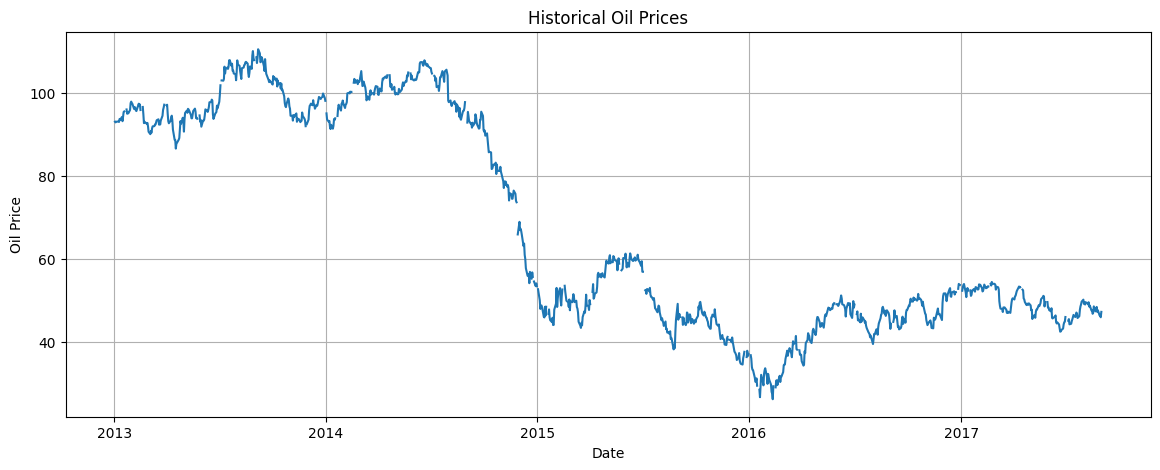

In [20]:
plt.figure(figsize=(14, 5))

plt.plot(oil["date"], oil["dcoilwtico"])

plt.title("Historical Oil Prices")
plt.xlabel("Date")
plt.ylabel("Oil Price")

plt.grid()
plt.show()

In [21]:
missing_oil = oil[oil["dcoilwtico"].isnull()].copy()

missing_oil["day_name"] = missing_oil["date"].dt.day_name()

print("Missing Values by Day:")
display(missing_oil["day_name"].value_counts())

print("\nFirst Missing Dates:")
display(missing_oil[["date", "day_name"]].head(15))

Missing Values by Day:


day_name
Monday       23
Friday        9
Thursday      7
Tuesday       2
Wednesday     2
Name: count, dtype: int64


First Missing Dates:


,date,day_name
0,2013-01-01,Tuesday
14,2013-01-21,Monday
34,2013-02-18,Monday
63,2013-03-29,Friday
104,2013-05-27,Monday
132,2013-07-04,Thursday
174,2013-09-02,Monday
237,2013-11-28,Thursday
256,2013-12-25,Wednesday
261,2014-01-01,Wednesday


In [22]:
oil = oil.sort_values("date")

oil["dcoilwtico"] = oil["dcoilwtico"].ffill().bfill()

print("Missing Values After Filling:", oil["dcoilwtico"].isnull().sum())

Missing Values After Filling: 0


### Key Findings

1. **Oil Price Range:** Oil prices ranged from approximately $26.19 to $110.62 during the observed period.

2. **Missing Values:** The dataset contains 43 missing oil prices (approximately 3.53%).

3. **Missing Dates Pattern:** Missing values occur on different weekdays, with Mondays accounting for the largest share (23 records).

4. **Price Trends:** Oil prices experienced a significant decline between 2014 and early 2016, followed by a partial recovery.

5. **Missing Value Treatment:** Missing values were handled using forward fill, with backward fill applied to the initial missing value.

### Conclusion

Oil prices represent a potentially useful external feature. Their historical trends and missing values should be considered during preprocessing and feature engineering.

## 11. Holidays Analysis

In this step, we examined holiday events to understand their distribution, categories, and potential impact on sales patterns.

In [23]:
print("Holiday Types:")
display(holidays["type"].value_counts())

print("\nHoliday Locales:")
display(holidays["locale"].value_counts())

print("\nTransferred Events:")
display(holidays["transferred"].value_counts())

Holiday Types:


type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64


Holiday Locales:


locale
National    174
Local       152
Regional     24
Name: count, dtype: int64


Transferred Events:


transferred
False    338
True      12
Name: count, dtype: int64

In [24]:
display(
    holidays.groupby(["locale", "type"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

,locale,type,Count
1,Local,Holiday,137
6,National,Holiday,60
5,National,Event,56
3,National,Additional,40
9,Regional,Holiday,24
0,Local,Additional,11
7,National,Transfer,8
4,National,Bridge,5
8,National,Work Day,5
2,Local,Transfer,4


### Key Findings

1. **Holiday Types:** The dataset contains 221 Holidays, 56 Events, 51 Additional events, 12 Transfers, 5 Bridge days, and 5 Work Days.

2. **Holiday Locales:** National events account for 174 records, followed by Local events (152) and Regional events (24).

3. **Transferred Events:** 12 events are marked as transferred, requiring special attention during feature engineering.

4. **Multiple Event Types:** Holiday records represent different types of events and should not all be treated as regular holidays.

5. **Geographical Impact:** Local and Regional holidays may affect specific stores depending on their locations.

### Conclusion

Holiday information may provide valuable temporal and geographical features for sales forecasting. Event types, geographical scope, and transferred dates must be handled carefully during preprocessing.

In [25]:
holiday_date_counts = holidays.groupby("date").size()

print("Dates with Multiple Events:")
display(
    holiday_date_counts[holiday_date_counts > 1]
    .sort_values(ascending=False)
    .head(10)
)

Dates with Multiple Events:


date
2014-06-25    4
2013-06-25    3
2012-06-25    3
2015-06-25    3
2016-06-25    3
2017-06-25    3
2012-12-24    2
2013-05-12    2
2012-12-31    2
2013-12-22    2
dtype: int64

In [26]:
print(
    "Dates with Multiple Events:",
    (holiday_date_counts > 1).sum()
)

Dates with Multiple Events: 31


### Multiple Events per Date

1. **Multiple Events:** The dataset contains 31 dates with more than one holiday event.

2. **Highest Event Count:** June 25, 2014 has the highest number of recorded events, with four events.

3. **Repeated Dates:** June 25 appears across multiple years, suggesting recurring events that may be relevant to sales patterns.

4. **Data Integration:** Multiple holiday records for the same date may cause row duplication when merging with the training dataset.

### Conclusion

Holiday data requires careful preprocessing before integration. Aggregating events by date and creating appropriate temporal features will help prevent unintended row duplication.


## 1. خلاصة فهم البيانات (Dataset Understanding Summary)

تعرفنا على مسابقة **Store Sales – Time Series Forecasting** وفهمنا هدفها الأساسي، وهو التنبؤ بالمبيعات اليومية لمختلف فئات المنتجات في مجموعة من المتاجر في الإكوادور.

حددنا المتغير المستهدف (`sales`)، والبيانات المتاحة، ومقياس التقييم المستخدم وهو `RMSLE`.

## 2. هيكل البيانات (Dataset Structure)

قمنا بتحميل وفحص مجموعات البيانات السبع:

- `train.csv`
- `test.csv`
- `stores.csv`
- `oil.csv`
- `holidays_events.csv`
- `transactions.csv`
- `sample_submission.csv`

تحتوي بيانات التدريب على 3,000,888 سجل، بينما تحتوي بيانات الاختبار على 28,512 سجل.

كما فحصنا أبعاد مجموعات البيانات، والأعمدة، وأنواع البيانات، والأعمدة المرشحة لتكون مفاتيح أساسية.

## 3. تحليل جودة البيانات (Data Quality Analysis)

- لم نعثر على أي صفوف مكررة بالكامل في مجموعات البيانات.
- لم نعثر على قيم مفقودة في مجموعتي التدريب والاختبار.
- تحتوي بيانات أسعار النفط على 43 قيمة مفقودة، بنسبة تقارب 3.53%.
- عالجنا القيم المفقودة في أسعار النفط باستخدام `Forward Fill` و`Backward Fill` بعد ترتيب البيانات حسب التاريخ.

## 4. تحليل المتغير المستهدف (Target Variable Analysis)

قمنا بفحص توزيع المتغير المستهدف (`sales`).

أهم النتائج:

- توزيع المبيعات منحرف بشدة نحو اليمين (Right-Skewed).
- قيمة المتوسط أعلى بكثير من الوسيط.
- يوجد 939,130 سجلًا بقيمة مبيعات تساوي صفرًا.
- لم نجد أي قيم مبيعات سالبة.
- أعلى قيمة مبيعات مسجلة هي 124,717.

كما رسمنا توزيع المبيعات قبل وبعد تطبيق التحويل اللوغاريتمي باستخدام `log1p()` لفهم التوزيع بصورة أفضل.

## 5. تحليل المبيعات حسب فئات المنتجات (Sales Patterns Across Product Families)

حللنا إحصائيات المبيعات لمختلف فئات المنتجات.

أهم النتائج:

- تحقق فئتا `GROCERY I` و`BEVERAGES` أعلى مستويات المبيعات.
- تختلف أحجام المبيعات بشكل كبير بين فئات المنتجات.
- بعض الفئات لديها نسب مرتفعة من الأيام التي لا تحقق فيها مبيعات.
- سجلت فئتا `BOOKS` و`BABY CARE` نسبًا مرتفعة جدًا من المبيعات الصفرية.

تشير هذه النتائج إلى أن فئة المنتج (`family`) من الخصائص المهمة لفهم سلوك المبيعات.

## 6. تحليل المتاجر (Store-Level Analysis)

فحصنا أداء المبيعات عبر المتاجر الـ54، ودرسنا بعض خصائصها الجغرافية والتشغيلية.

كما استكشفنا العلاقة بين المبيعات وخصائص المتاجر، ومنها:

- المدينة (`city`).
- الولاية أو المنطقة (`state`).
- نوع المتجر (`type`).
- المجموعة (`cluster`).

أظهرت النتائج وجود اختلافات واضحة في أداء المبيعات ونسب المبيعات الصفرية بين المتاجر.

## 7. تحليل المعاملات (Transactions Analysis)

درسنا أنماط المعاملات اليومية عبر المتاجر.

قمنا بتجميع المبيعات اليومية باستخدام `date` و`store_nbr`، ثم دمجنا النتائج مع بيانات المعاملات.

بلغ معامل الارتباط بين المبيعات اليومية وعدد المعاملات حوالي **0.837**.

يشير ذلك إلى وجود علاقة إيجابية قوية بين عدد معاملات العملاء وحجم المبيعات.

وبالتالي، قد تكون بيانات `transactions` مفيدة في بناء النموذج، بشرط التأكد من توفرها خلال فترة التنبؤ.

## 8. تحليل أسعار النفط (Oil Prices Analysis)

فحصنا أسعار النفط التاريخية باستخدام المتغير `dcoilwtico`.

أهم النتائج:

- تراوحت أسعار النفط تقريبًا بين 26.19 و110.62.
- تحتوي البيانات على 43 قيمة مفقودة.
- شهدت أسعار النفط انخفاضًا ملحوظًا بين عام 2014 وبداية عام 2016، تلاه تعافٍ جزئي.
- عالجنا القيم المفقودة باستخدام `Forward Fill` و`Backward Fill`.

قد تمثل أسعار النفط متغيرًا خارجيًا مفيدًا لالتقاط بعض التغيرات الاقتصادية العامة.

## 9. تحليل العطلات والأحداث (Holidays Analysis)

فحصنا بيانات العطلات والأحداث لفهم توزيعها وتصنيفاتها وتأثيرها المحتمل على أنماط المبيعات.

أهم النتائج:

- تحتوي البيانات على 350 سجلًا تمثل 312 تاريخًا فريدًا.
- يوجد 31 تاريخًا يحتوي على أكثر من حدث واحد.
- تصنف الأحداث إلى `National` و`Local` و`Regional`.
- تتضمن أنواع الأحداث `Holiday` و`Event` و`Additional` و`Transfer` و`Bridge` و`Work Day`.
- بعض العطلات يتم نقلها إلى تواريخ أخرى.

**ملاحظة مهمة لمرحلة Preprocessing:**

إن دمج بيانات العطلات مباشرة مع بيانات المبيعات باستخدام `date` قد يؤدي إلى تكرار سجلات المبيعات؛ لأن التاريخ الواحد قد يحتوي على أكثر من حدث.

لذلك، يجب معالجة بيانات العطلات قبل الدمج، مثل تجميع الأحداث حسب التاريخ أو تحويلها إلى Features مناسبة.

كذلك، يجب مراعاة المواقع الجغرافية للمتاجر عند التعامل مع العطلات المحلية والإقليمية، لأنها لا تؤثر بالضرورة على جميع المتاجر.

أما العطلات المنقولة (`transferred = True`)، فيجب التعامل معها بحذر؛ فالتاريخ الأصلي يُعامل غالبًا كيوم عادي، ويجب تحديد تاريخ الاحتفال الفعلي من خلال الحدث المقابل من نوع `Transfer`.

---

# الخلاصة العامة والاعتبارات المستقبلية (General Findings & Future Considerations)

ساعدنا اليوم الأول على فهم هيكل البيانات، وتوزيع المتغير المستهدف، وجودة البيانات، والعلاقات الأولية بين مجموعات البيانات المختلفة.

كما حددنا مجموعة من النقاط المهمة التي سنحتاج إلى دراستها في المراحل القادمة.

### 1. المعالجة المسبقة وهندسة الخصائص (Preprocessing & Feature Engineering)

سنحتاج إلى دراسة ومعالجة الأمور التالية:

- **العروض الترويجية (Promotion Analysis):** فحص توزيع `onpromotion` وفهم علاقته بالمبيعات.
- **الخصائص الزمنية (Temporal Features):** استخراج خصائص مثل `Day of Week` و`Month` ودراسة الأنماط الموسمية (`Seasonality`).
- **خصائص العطلات (Holiday Features):** معالجة بيانات العطلات بصورة صحيحة قبل دمجها مع بيانات المبيعات، لتجنب تكرار السجلات أو إسناد الأحداث إلى تواريخ غير صحيحة.
- **القيم المفقودة (Missing Values):** دراسة الاستراتيجيات المناسبة لمعالجة القيم المفقودة في مجموعات البيانات الإضافية.

### 2. استراتيجية التحقق ومنع تسرب البيانات (Validation Strategy & Data Leakage)

بما أن المسألة تتعلق بالتنبؤ بالسلاسل الزمنية، فإن استخدام تقسيم عشوائي للبيانات (`Random Train-Validation Split`) قد يؤدي إلى نتائج مضللة.

يجب تصميم استراتيجية تحقق تراعي الترتيب الزمني للبيانات، وتمنع تسرب المعلومات المستقبلية إلى بيانات التدريب.

كما يجب التأكد من أن جميع الخصائص المستخدمة أثناء التحقق ستكون متاحة بالفعل عند تنفيذ التنبؤ.

### 3. الخصائص الإضافية (Additional Features)

قد توفر مجموعات البيانات التالية معلومات مفيدة لتحسين التنبؤ:

- خصائص المتاجر.
- أسعار النفط.
- المعاملات اليومية.
- العطلات والأحداث.
- الأنشطة الترويجية.

لكن يجب تقييم فائدة هذه الخصائص من خلال استراتيجية تحقق سليمة، وليس بناءً على الافتراضات فقط.

### الخاتمة (Conclusion)

كشف التحليل الأولي عن اختلافات واضحة في سلوك المبيعات بين فئات المنتجات والمتاجر والفترات الزمنية.

كما أظهر أهمية دراسة الأنماط الزمنية، والعروض الترويجية، والمعاملات، وأسعار النفط، والعطلات والأحداث.

ستركز المرحلة القادمة على المعالجة المسبقة للبيانات، وهندسة الخصائص الزمنية، وتصميم استراتيجية تحقق موثوقة قبل البدء في تطوير النماذج التنبؤية.

---

## 1. Dataset Understanding Summary

We explored the Store Sales – Time Series Forecasting competition and understood its main objective: predicting daily sales for different product families across multiple stores in Ecuador.

We identified the target variable (`sales`), the available datasets, and the evaluation metric, `RMSLE`.

## 2. Dataset Structure

We loaded and examined all seven datasets:

- `train.csv`
- `test.csv`
- `stores.csv`
- `oil.csv`
- `holidays_events.csv`
- `transactions.csv`
- `sample_submission.csv`

The training dataset contains 3,000,888 records, while the test dataset contains 28,512 records.

We also examined dataset dimensions, columns, data types, and potential key columns.

## 3. Data Quality Analysis

- No completely duplicated rows were found in any dataset.
- No missing values were found in the training or test datasets.
- The oil dataset contains 43 missing values (approximately 3.53%).
- Missing oil prices were handled using forward fill and backward fill after sorting the data by date.

## 4. Target Variable Analysis

We examined the distribution of the target variable (`sales`).

Key observations:

- Sales are highly right-skewed.
- The mean is significantly higher than the median.
- Approximately 939,130 records have zero sales.
- No negative sales values were found.
- The maximum recorded sales value is 124,717.

We also visualized the original and log-transformed sales distributions using `log1p()` to better understand the target distribution.

## 5. Sales Patterns Across Product Families

We analyzed sales statistics across different product families.

Key observations:

- `GROCERY I` and `BEVERAGES` have the highest sales volumes.
- Sales volumes vary considerably across product families.
- Some product families have very high percentages of zero-sales records.
- `BOOKS` and `BABY CARE` have particularly high zero-sales percentages.

These findings indicate that product family (`family`) is an important feature for understanding sales behavior.

## 6. Store-Level Analysis

We examined sales performance across the 54 stores and investigated their geographical and operational characteristics.

We also explored relationships between sales and store attributes, including:

- City.
- State.
- Store type.
- Cluster.

The results revealed considerable differences in sales performance and zero-sales percentages across stores.

## 7. Transactions Analysis

We investigated transaction patterns across stores.

We aggregated daily sales using `date` and `store_nbr`, then merged the results with the transactions dataset.

The resulting correlation between daily sales and transactions was approximately **0.837**.

This indicates a strong positive relationship between customer transaction volume and sales.

Therefore, transactions may be a useful feature, provided they are available during the prediction period.

## 8. Oil Prices Analysis

We examined historical oil prices represented by the `dcoilwtico` variable.

Key observations:

- Oil prices ranged approximately from 26.19 to 110.62.
- The dataset contains 43 missing values.
- Oil prices experienced a significant decline between 2014 and early 2016, followed by a partial recovery.
- Missing values were handled using forward fill and backward fill.

Oil prices may represent a useful external feature for capturing broader economic conditions.

## 9. Holidays Analysis

We examined holiday events to understand their distribution, categories, and potential impact on sales patterns.

Key observations:

- The dataset contains 350 event records representing 312 unique dates.
- There are 31 dates with multiple events.
- Events are classified into National, Local, and Regional categories.
- Event types include `Holiday`, `Event`, `Additional`, `Transfer`, `Bridge`, and `Work Day`.
- Some holidays are transferred to different dates.

**Important consideration for preprocessing:**

Directly merging the holidays dataset with sales data using `date` may duplicate sales records because multiple events can occur on the same date.

Therefore, holiday events should be processed before merging, for example, by aggregating events by date or transforming them into appropriate features.

Local and regional holidays should also be matched with the corresponding store locations, as they do not necessarily affect all stores.

Transferred holidays (`transferred = True`) require special handling. The original date should generally be treated as a normal day, while the actual celebration date should be identified through the corresponding `Transfer` event.

---

# General Findings & Future Considerations

Day 1 helped us understand the dataset structure, target distribution, data quality, and initial relationships between the available datasets.

Several important considerations were identified for the next stages.

### 1. Preprocessing & Feature Engineering

We will need to investigate and handle the following:

- **Promotion Analysis:** Examine the distribution of `onpromotion` and understand its relationship with sales.
- **Temporal Features:** Extract features such as `Day of Week` and `Month`, and investigate seasonal patterns (`Seasonality`).
- **Holiday Features:** Properly process holiday events before merging them with sales data to avoid duplicated records or incorrect event assignments.
- **Missing Values:** Investigate appropriate strategies for handling missing values in additional datasets.

### 2. Validation Strategy & Data Leakage

Since this is a time-series forecasting problem, a random train-validation split may produce misleading results.

We must develop a time-aware validation strategy that respects chronological order and prevents future information from leaking into the training process.

We must also verify that all features used during validation would realistically be available at prediction time.

### 3. Additional Features

The following datasets may provide useful information for improving predictions:

- Store characteristics.
- Oil prices.
- Daily transactions.
- Holiday events.
- Promotional activities.

However, their usefulness must be evaluated through a reliable validation strategy rather than assumptions.

### Conclusion

The initial analysis revealed considerable differences in sales behavior across product families, stores, and time periods.

It also highlighted the importance of investigating temporal patterns, promotional activities, transactions, oil prices, and holiday events.

The next stage will focus on data preprocessing, temporal feature engineering, and designing a reliable validation strategy before developing predictive models.

## 12. Temporal Analysis & Feature Engineering

### 12.1 Date Preparation

Convert the date columns into datetime format to enable temporal analysis and time-based feature extraction.

In [27]:
# Convert date columns to datetime
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])

# Check data types
print("Train date dtype:", train['date'].dtype)
print("Test date dtype:", test['date'].dtype)

Train date dtype: datetime64[ns]
Test date dtype: datetime64[ns]


In [28]:
# Extract time-based features
for df in [train, test]:
    df['year'] = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['day_of_week'] = df['date'].dt.dayofweek
    df['day_of_year'] = df['date'].dt.dayofyear
    df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)

# Display the extracted features
train[['date', 'year', 'month', 'day',
       'day_of_week', 'day_of_year', 'week_of_year']].head()

,date,year,month,day,day_of_week,day_of_year,week_of_year
0,2013-01-01,2013,1,1,1,1,1
1,2013-01-01,2013,1,1,1,1,1
2,2013-01-01,2013,1,1,1,1,1
3,2013-01-01,2013,1,1,1,1,1
4,2013-01-01,2013,1,1,1,1,1


### 12.2 Temporal Sales Analysis

Analyze daily sales trends to identify long-term patterns, fluctuations, and potential seasonality in the training data.

In [29]:
# Aggregate total sales by date
daily_sales = train.groupby('date')['sales'].sum().reset_index()

# Display the first rows
daily_sales.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


In [30]:
# Aggregate total sales by date
daily_sales = train.groupby('date')['sales'].sum().reset_index()

# Display the first rows
daily_sales.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


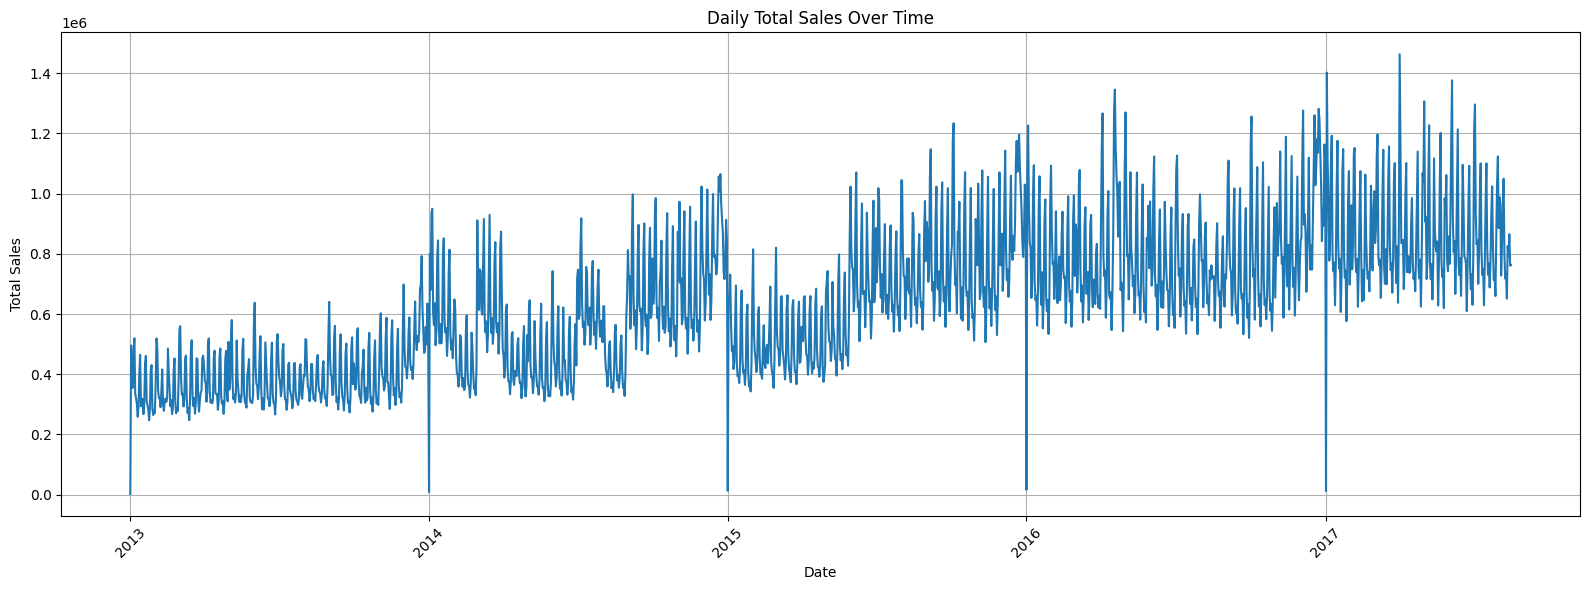

In [31]:
# Plot daily sales trend
plt.figure(figsize=(16, 6))

plt.plot(daily_sales['date'], daily_sales['sales'])

plt.title('Daily Total Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [32]:
# Identify dates with zero total sales
zero_sales_days = daily_sales[daily_sales['sales'] == 0]

print("Number of zero-sales days:", len(zero_sales_days))

zero_sales_days.head(20)

Number of zero-sales days: 0


,date,sales


In [33]:
# Display the dates and sales around the beginning of each year
for year in range(2013, 2018):
    print(f"\nYear: {year}")
    display(
        daily_sales[
            (daily_sales['date'].dt.year == year) &
            (daily_sales['date'].dt.month == 1)
        ].head(5)
    )


Year: 2013


,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229



Year: 2014


,date,sales
364,2014-01-01,8602.065404
365,2014-01-02,801011.226041
366,2014-01-03,680672.845603
367,2014-01-04,936628.886604
368,2014-01-05,949618.788940



Year: 2015


,date,sales
728,2015-01-01,12773.616980
729,2015-01-02,657763.391981
730,2015-01-03,648880.686926
731,2015-01-04,730923.776022
732,2015-01-05,569267.297960



Year: 2016


,date,sales
1092,2016-01-01,1.643339e+04
1093,2016-01-02,1.066677e+06
1094,2016-01-03,1.226736e+06
1095,2016-01-04,9.559569e+05
1096,2016-01-05,8.353204e+05



Year: 2017


,date,sales
1457,2017-01-01,1.208250e+04
1458,2017-01-02,1.402306e+06
1459,2017-01-03,1.104377e+06
1460,2017-01-04,9.900935e+05
1461,2017-01-05,7.776210e+05


### 12.2.1 Investigating New Year's Day Sales

In [34]:
# Check New Year's Day holiday records
new_year_holidays = holidays[
    (holidays['date'].dt.month == 1) &
    (holidays['date'].dt.day == 1)
]

new_year_holidays.sort_values('date')

,date,type,locale,locale_name,description,transferred
41,2013-01-01,Holiday,National,Ecuador,Primer dia del ano,False
92,2014-01-01,Holiday,National,Ecuador,Primer dia del ano,False
159,2015-01-01,Holiday,National,Ecuador,Primer dia del ano,False
211,2016-01-01,Holiday,National,Ecuador,Primer dia del ano,False
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True


**Key Finding:**

Daily sales show a consistent sharp decline on January 1 across the observed years. The holidays dataset confirms that this date is recorded as a national holiday in Ecuador. This suggests that New Year's Day may significantly affect sales, although the holiday's exact impact should be evaluated further during feature engineering and model validation.

### 12.3 Monthly Sales Analysis

In [35]:
# Calculate average daily sales for each month
monthly_sales = (
    daily_sales.groupby(daily_sales['date'].dt.month)['sales']
    .mean()
    .reset_index()
)

# Rename columns
monthly_sales.columns = ['month', 'avg_daily_sales']

# Display results
monthly_sales

,month,avg_daily_sales
0,1,609304.208495
1,2,571895.244225
2,3,627280.562239
3,4,604454.117050
4,5,609026.690473
5,6,630111.355279
6,7,666858.456059
7,8,600520.696680
8,9,645613.999338
9,10,645809.509319


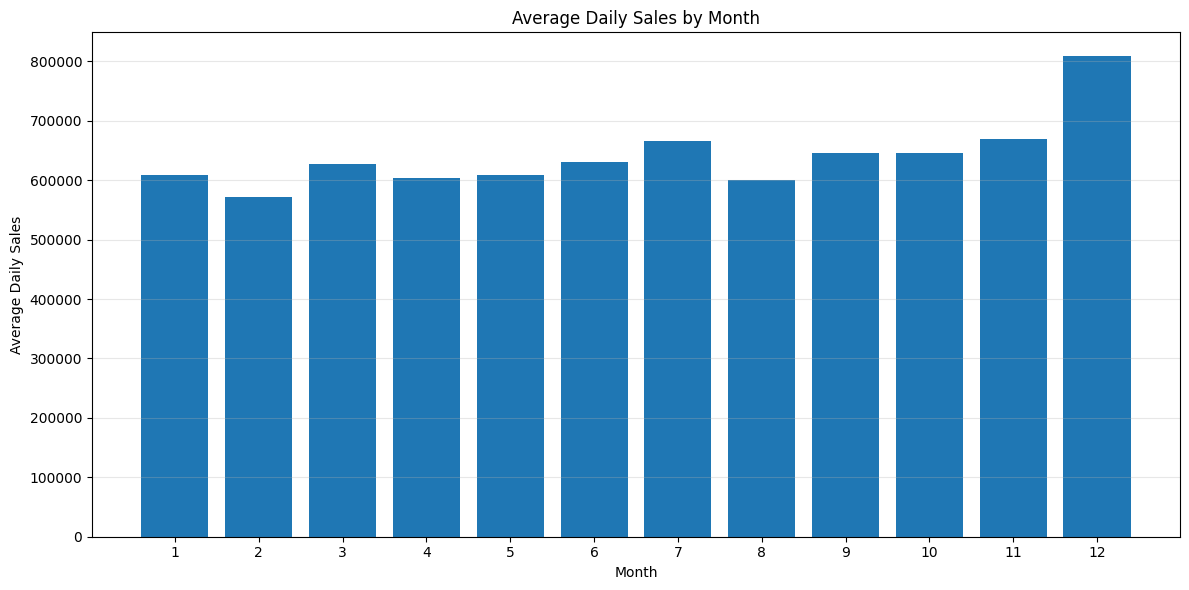

In [36]:
# Plot average daily sales by month
plt.figure(figsize=(12, 6))

plt.bar(monthly_sales['month'], monthly_sales['avg_daily_sales'])

plt.title('Average Daily Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')
plt.xticks(range(1, 13))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# Aggregate average daily sales by year and month
monthly_yearly_sales = (
    daily_sales.groupby([
        daily_sales['date'].dt.year.rename('year'),
        daily_sales['date'].dt.month.rename('month')
    ])['sales']
    .mean()
    .reset_index()
)

# Create a pivot table
monthly_pivot = monthly_yearly_sales.pivot(
    index='month',
    columns='year',
    values='sales'
)

monthly_pivot

year,2013,2014,2015,2016,2017
month,,,,,
1,333149.185062,610052.925852,480545.872813,773477.576949,849295.481797
2,344962.849194,429941.165499,490799.851728,756807.200035,830361.156248
3,368661.194758,656954.323112,503180.887689,746186.480123,861419.925512
4,366448.824600,428708.368572,498502.272359,865434.170065,863176.949652
5,374119.484098,431605.976168,571947.362720,799336.524523,868124.104858
6,389644.802075,443998.605767,720512.011708,740307.286013,856094.070833
7,363141.955086,626512.614317,716439.323830,756860.401068,871337.985995
8,378638.352241,447908.916744,740763.685203,724271.429610,828888.196052
9,393097.774396,667413.870460,774696.082597,747248.269900,NaN


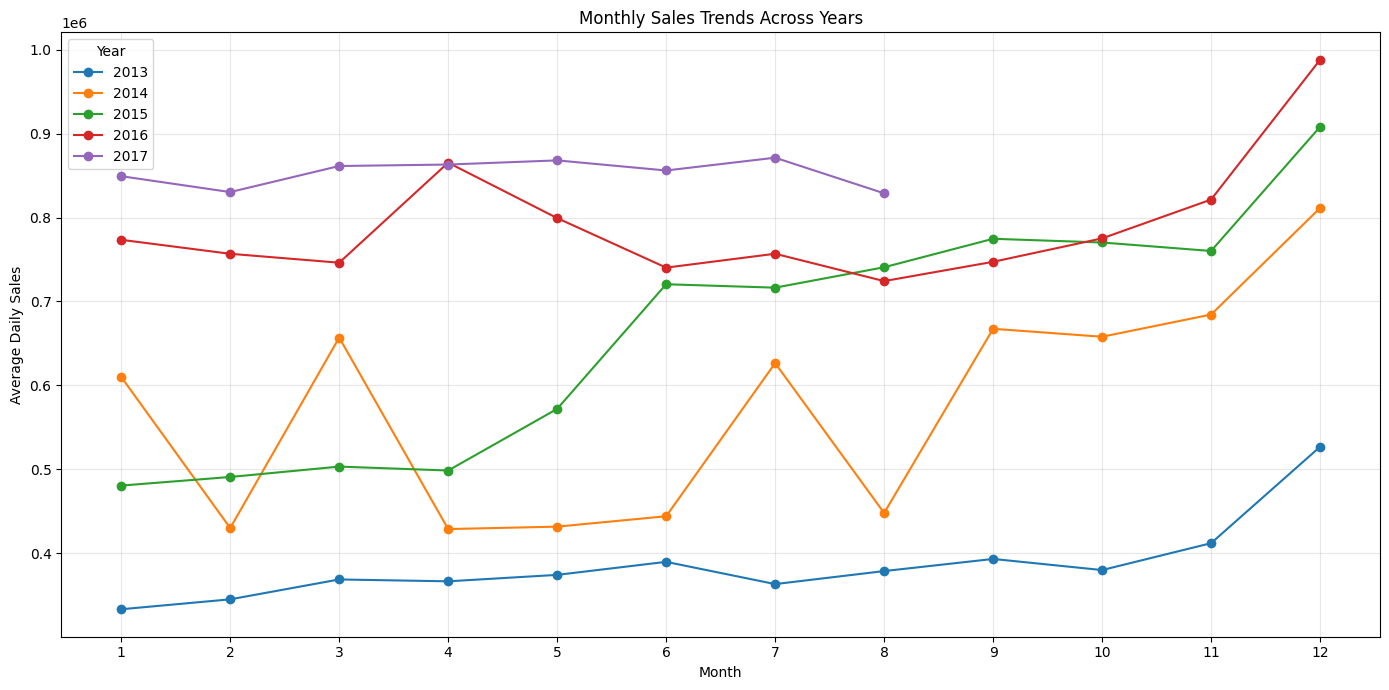

In [38]:
# Plot monthly sales trends across years
monthly_pivot.plot(
    figsize=(14, 7),
    marker='o'
)

plt.title('Monthly Sales Trends Across Years')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

**Key Findings:**

- Average daily sales generally increased across the years, indicating a clear upward sales trend.
- December recorded the highest average daily sales in each complete year from 2013 to 2016.
- Monthly sales patterns vary across years, suggesting that seasonal effects are not entirely consistent.
- The noticeable increase in December suggests a potential seasonal pattern that may be useful for forecasting.
- 2017 contains data only from January to August, so comparisons with the remaining months are not possible.

**Conclusion:**

The analysis reveals both long-term growth (Trend) and potential recurring seasonal patterns (Seasonality). Both effects should be considered during feature engineering and model development.

### 12.4 Day-of-Week Analysis

In [39]:
# Calculate average daily sales by day of week
weekday_sales = (
    daily_sales.groupby(daily_sales['date'].dt.dayofweek)['sales']
    .mean()
    .reset_index()
)

# Rename columns
weekday_sales.columns = ['day_of_week', 'avg_daily_sales']

# Map weekday numbers to names
weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

weekday_sales['day_name'] = weekday_sales['day_of_week'].map(weekday_names)

weekday_sales

,day_of_week,avg_daily_sales,day_name
0,0,617542.713052,Monday
1,1,569926.087922,Tuesday
2,2,593244.553472,Wednesday
3,3,505269.201115,Thursday
4,4,579574.361085,Friday
5,5,772205.593943,Saturday
6,6,825218.121579,Sunday


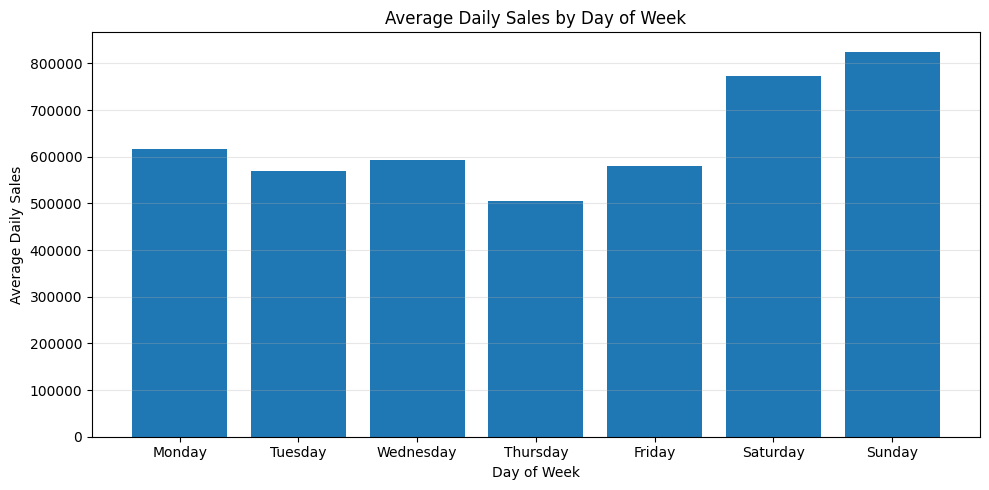

In [40]:
# Plot average daily sales by weekday
plt.figure(figsize=(10, 5))

plt.bar(weekday_sales['day_name'], weekday_sales['avg_daily_sales'])

plt.title('Average Daily Sales by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Daily Sales')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Key Findings:**

- Sunday records the highest average daily sales, followed by Saturday.
- Thursday has the lowest average daily sales.
- Sales patterns vary considerably across weekdays.
- The observed differences suggest a strong weekly pattern that may provide useful predictive information.

The `day_of_week` feature may help the model capture recurring weekly sales patterns.

### 12.5 Promotion Analysis

Analyze the relationship between promotional activities and sales to investigate how promotions are associated with product demand.

In [41]:
# Analyze sales by promotion count
promotion_analysis = (
    train.groupby('onpromotion')['sales']
    .agg(['mean', 'median', 'count'])
    .reset_index()
)

# Display the first 15 rows
promotion_analysis.head(15)

,onpromotion,mean,median,count
0,0,158.246681,3.0000,2389559
1,1,467.556532,145.3480,174551
2,2,662.925632,245.3115,79386
3,3,871.408092,325.3910,45862
4,4,969.916135,346.0000,31659
5,5,1010.659835,348.0000,24540
6,6,1022.854287,358.0000,22079
7,7,1022.567058,358.3420,18917
8,8,1174.757003,420.0000,15587
9,9,1258.733993,434.0000,13850


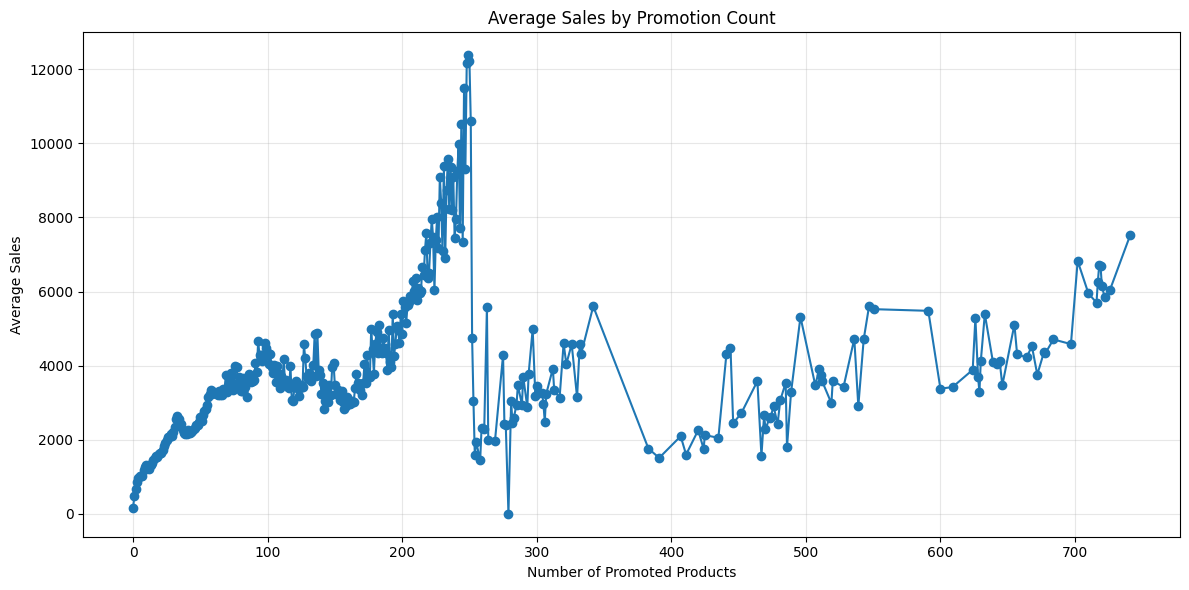

In [42]:
# Plot average sales by promotion count
plt.figure(figsize=(12, 6))

plt.plot(
    promotion_analysis['onpromotion'],
    promotion_analysis['mean'],
    marker='o'
)

plt.title('Average Sales by Promotion Count')
plt.xlabel('Number of Promoted Products')
plt.ylabel('Average Sales')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Key Findings:**

- Average sales generally increase with the number of promoted products.
- A noticeable increase in average sales occurs at moderate promotion counts.
- At higher promotion counts, the average sales become highly variable.
- The number of observations decreases substantially as promotion counts increase, making estimates at higher values less reliable.
- Extreme sales values may influence the calculated averages.

**Conclusion:**

Promotional activity appears to be associated with higher sales. However, this relationship should be interpreted cautiously due to differences in observation counts and potential outliers. Further analysis is needed to evaluate its predictive value.

### 12.6 Promotion Analysis by Product Family

In [43]:
# Analyze promotion impact across product families
family_promotion = (
    train.groupby('family')
    .apply(
        lambda x: x.groupby('onpromotion')['sales'].mean(),
        include_groups=False
    )
    .unstack()
)

# Calculate average sales with and without promotions
family_promotion = family_promotion[[0, 1]]
family_promotion.columns = ['no_promotion', 'with_promotion']

# Calculate percentage difference
family_promotion['sales_difference_pct'] = (
    (family_promotion['with_promotion'] - family_promotion['no_promotion'])
    / family_promotion['no_promotion'].replace(0, np.nan)
) * 100

family_promotion.sort_values(
    'sales_difference_pct',
    ascending=False
)

,no_promotion,with_promotion,sales_difference_pct
family,,,
SCHOOL AND OFFICE SUPPLIES,1.022018,17.597816,1621.868874
BABY CARE,0.109624,1.660377,1414.604792
PET SUPPLIES,3.507379,15.852740,351.982496
HOME AND KITCHEN II,10.275239,36.150215,251.818721
HOME APPLIANCES,0.456876,1.396552,205.673959
HOME CARE,101.956009,309.011856,203.083516
PRODUCE,792.101911,2103.026708,165.499512
PLAYERS AND ELECTRONICS,6.081521,16.062069,164.112686
BEAUTY,3.078452,8.079021,162.437739


**Key Findings:**

- Promotional activity is associated with higher average sales across most product families.
- The magnitude of this association varies considerably between product families.
- SCHOOL AND OFFICE SUPPLIES and BABY CARE show particularly large percentage differences, partly because their baseline sales are very low.
- BOOKS has no observations with `onpromotion = 1`, indicating that no promotional activity was recorded for this family in the training data.
- GROCERY I has relatively high average sales in both promotional and non-promotional observations, but its percentage difference is comparatively modest.

**Conclusion:**

The relationship between promotional activity and sales differs across product families. Therefore, promotional features should be considered alongside product family information during model development.

These comparisons are descriptive and do not establish a causal relationship.

### 12.7 Temporal Feature Engineering

In [44]:
# Add additional temporal features
for df in [train, test]:

    # Weekend indicator (Saturday and Sunday)
    df['is_weekend'] = (df['date'].dt.dayofweek >= 5).astype(int)

    # Quarter of the year
    df['quarter'] = df['date'].dt.quarter

    # Cyclical encoding for month
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

    # Cyclical encoding for day of week
    df['day_of_week_sin'] = np.sin(
        2 * np.pi * df['day_of_week'] / 7
    )
    df['day_of_week_cos'] = np.cos(
        2 * np.pi * df['day_of_week'] / 7
    )

# Display the new features
train[[
    'date', 'year', 'month', 'day_of_week',
    'is_weekend', 'quarter',
    'month_sin', 'month_cos',
    'day_of_week_sin', 'day_of_week_cos'
]].head()

,date,year,month,day_of_week,is_weekend,quarter,month_sin,month_cos,day_of_week_sin,day_of_week_cos
0,2013-01-01,2013,1,1,0,1,0.5,0.866025,0.781831,0.62349
1,2013-01-01,2013,1,1,0,1,0.5,0.866025,0.781831,0.62349
2,2013-01-01,2013,1,1,0,1,0.5,0.866025,0.781831,0.62349
3,2013-01-01,2013,1,1,0,1,0.5,0.866025,0.781831,0.62349
4,2013-01-01,2013,1,1,0,1,0.5,0.866025,0.781831,0.62349


**Key Findings:**

- Extracted calendar features including year, month, day, day of week, day of year, and week of year.
- Added `is_weekend` to distinguish weekdays from weekends.
- Added `quarter` to represent quarterly patterns.
- Applied Cyclical Encoding using sine and cosine transformations to represent the periodic nature of months and weekdays.
- Applied the same feature transformations to both training and test datasets to maintain consistency.

**Conclusion:**

These features provide the model with information about long-term trends, seasonal patterns, and recurring weekly behavior. Their actual predictive value will be evaluated during model validation.

### 12.8 Checking Feature Consistency

In [45]:
# Define engineered temporal features
temporal_features = [
    'year',
    'month',
    'day',
    'day_of_week',
    'day_of_year',
    'week_of_year',
    'is_weekend',
    'quarter',
    'month_sin',
    'month_cos',
    'day_of_week_sin',
    'day_of_week_cos'
]

# Check feature consistency
print("Train features available:", 
      set(temporal_features).issubset(train.columns))

print("Test features available:", 
      set(temporal_features).issubset(test.columns))

# Check missing values
print("\nTrain missing values:")
print(train[temporal_features].isnull().sum().sum())

print("\nTest missing values:")
print(test[temporal_features].isnull().sum().sum())

Train features available: True
Test features available: True

Train missing values:
0

Test missing values:
0


**Validation Results:**

- All engineered temporal features are available in both training and test datasets.
- No missing values were found in the newly created temporal features.
- Both datasets use consistent feature transformations.

**Conclusion:**

The temporal feature engineering process was successfully applied to both datasets.

### 12.9 Time-Based Validation Strategy

A chronological validation strategy will be used to simulate the actual forecasting task and prevent future data leakage.

In [46]:
# Define validation period
validation_start = '2017-07-31'

# Split data chronologically
train_set = train[train['date'] < validation_start].copy()

valid_set = train[train['date'] >= validation_start].copy()

# Display date ranges and shapes
print("Training period:")
print(train_set['date'].min(), "to", train_set['date'].max())

print("\nValidation period:")
print(valid_set['date'].min(), "to", valid_set['date'].max())

print("\nTraining shape:", train_set.shape)
print("Validation shape:", valid_set.shape)

Training period:
2013-01-01 00:00:00 to 2017-07-30 00:00:00

Validation period:
2017-07-31 00:00:00 to 2017-08-15 00:00:00

Training shape: (2972376, 18)
Validation shape: (28512, 18)


**Validation Strategy:**

- Used a chronological split instead of random sampling.
- Training data ends on July 30, 2017.
- Validation covers the following 16 days, from July 31 to August 15, 2017.
- The validation period matches the 16-day forecasting horizon of the competition test set.

**Conclusion:**

This approach provides a realistic evaluation framework while preserving chronological order and reducing the risk of temporal data leakage.

### 12.10 Lag Features & Rolling Statistics

Lag features and rolling statistics capture historical sales patterns for each store and product family.

#### 12.10.1 Creating Lag Features

Historical sales values from previous periods are used to capture recurring demand patterns for each store and product family.

In [47]:
# Sort data chronologically
train = train.sort_values(
    ['store_nbr', 'family', 'date']
).copy()

# Group sales by store and product family
grouped_sales = train.groupby(['store_nbr', 'family'])['sales']

# Create lag features
train['lag_16'] = grouped_sales.shift(16)
train['lag_30'] = grouped_sales.shift(30)
train['lag_365'] = grouped_sales.shift(365)

# Create rolling mean using only information
# available before the 16-day forecasting horizon
train['rolling_mean_16'] = grouped_sales.transform(
    lambda x: x.shift(16).rolling(window=16).mean()
)

# Display the new features
train[[
    'date', 'store_nbr', 'family', 'sales',
    'lag_16', 'lag_30', 'lag_365',
    'rolling_mean_16'
]].tail(10)

,date,store_nbr,family,sales,lag_16,lag_30,lag_365,rolling_mean_16
2984717,2017-08-06,54,SEAFOOD,0.0,0.0,2.0,2.0,3.2500
2986499,2017-08-07,54,SEAFOOD,0.0,3.0,9.0,3.0,3.3125
2988281,2017-08-08,54,SEAFOOD,12.0,5.0,6.0,5.0,3.5000
2990063,2017-08-09,54,SEAFOOD,4.0,1.0,10.0,1.0,3.0000
2991845,2017-08-10,54,SEAFOOD,2.0,7.0,3.0,1.0,3.0625
2993627,2017-08-11,54,SEAFOOD,0.0,3.0,1.0,0.0,2.6250
2995409,2017-08-12,54,SEAFOOD,1.0,2.0,0.0,2.0,2.5625
2997191,2017-08-13,54,SEAFOOD,2.0,4.0,0.0,4.0,2.7500
2998973,2017-08-14,54,SEAFOOD,0.0,4.0,2.0,2.0,3.0000
3000755,2017-08-15,54,SEAFOOD,3.0,4.0,5.0,1.0,3.2500


#### 12.10.2 Checking Missing Values

Lag and rolling features naturally produce missing values at the beginning of each store-family time series because insufficient historical observations are available.

In [48]:
# Check missing values in lag and rolling features
lag_features = [
    'lag_16',
    'lag_30',
    'lag_365',
    'rolling_mean_16'
]

missing_summary = pd.DataFrame({
    'missing_count': train[lag_features].isnull().sum(),
    'missing_percentage': train[lag_features].isnull().mean() * 100
})

missing_summary

,missing_count,missing_percentage
lag_16,28512,0.950119
lag_30,53460,1.781473
lag_365,650430,21.674584
rolling_mean_16,55242,1.840855


### 12.10.3 Inspecting Missing Values by Period

Lag and rolling features may contain missing values due to insufficient historical observations. We will inspect their distribution across training and validation periods before deciding how to handle them.

In [49]:
# Check missing values in training and validation periods

for name, data in [
    ('Training', train[train['date'] <= '2017-07-30']),
    ('Validation', train[train['date'] >= '2017-07-31'])
]:
    print(f'\n{name} Missing Values:')
    print(data[lag_features].isnull().sum())


Training Missing Values:
lag_16              28512
lag_30              53460
lag_365            650430
rolling_mean_16     55242
dtype: int64

Validation Missing Values:
lag_16             0
lag_30             0
lag_365            0
rolling_mean_16    0
dtype: int64


### 12.10.4 Handling Missing Values

Missing values in lag and rolling features are caused by insufficient historical observations at the beginning of each store-family time series.

Since these missing values are expected and the validation period contains no missing values, we will preserve them for now and use a model that supports missing values natively.

Dropping these rows would result in unnecessary data loss, particularly for the 365-day lag feature.

### 12.11 Data Leakage Inspection

Data leakage occurs when information that would not be available at prediction time is used during model training or validation.

We will inspect the temporal ordering and lag/rolling feature construction to ensure that all features rely only on historical information.

#### 12.11.1 Checking Temporal Ordering

In [50]:
# Check chronological ordering within each store-family group
is_sorted = (
    train.groupby(['store_nbr', 'family'])['date']
    .apply(lambda x: x.is_monotonic_increasing)
)

print("All groups chronologically sorted:", is_sorted.all())
print("Unsorted groups:", (~is_sorted).sum())

All groups chronologically sorted: True
Unsorted groups: 0


#### 12.11.2 Verifying Lag Feature Alignment

Verify that lag features correctly reference historical sales values within each store-family group, ensuring that no future target information is introduced.

In [51]:
# Select one store-family group
sample_group = train[
    (train['store_nbr'] == 1) &
    (train['family'] == 'AUTOMOTIVE')
].copy()

# Compare current sales with sales from 16 days earlier
sample_group['expected_lag_16'] = sample_group['sales'].shift(16)

# Check lag alignment
sample_group['lag_match'] = np.isclose(
    sample_group['lag_16'],
    sample_group['expected_lag_16'],
    equal_nan=True
)

print("All lag_16 values correctly aligned:",
      sample_group['lag_match'].all())

sample_group[[
    'date', 'sales', 'lag_16', 'expected_lag_16', 'lag_match'
]].tail(10)

All lag_16 values correctly aligned: True


,date,sales,lag_16,expected_lag_16,lag_match
2983068,2017-08-06,6.0,10.0,10.0,True
2984850,2017-08-07,7.0,8.0,8.0,True
2986632,2017-08-08,4.0,0.0,0.0,True
2988414,2017-08-09,7.0,4.0,4.0,True
2990196,2017-08-10,9.0,10.0,10.0,True
2991978,2017-08-11,1.0,2.0,2.0,True
2993760,2017-08-12,6.0,5.0,5.0,True
2995542,2017-08-13,1.0,7.0,7.0,True
2997324,2017-08-14,1.0,4.0,4.0,True
2999106,2017-08-15,4.0,1.0,1.0,True


#### 12.11.3 Verifying Rolling Feature Alignment

Verify that the rolling mean feature uses only historical sales observations and is correctly aligned within each store-family time series.

In [52]:
# Calculate the expected rolling mean for the sample group
sample_group['expected_rolling_mean_16'] = (
    sample_group['sales']
    .shift(16)
    .rolling(window=16)
    .mean()
)

# Compare the calculated values with the existing feature
sample_group['rolling_match'] = np.isclose(
    sample_group['rolling_mean_16'],
    sample_group['expected_rolling_mean_16'],
    equal_nan=True
)

print(
    "All rolling_mean_16 values correctly aligned:",
    sample_group['rolling_match'].all()
)

sample_group[[
    'date',
    'rolling_mean_16',
    'expected_rolling_mean_16',
    'rolling_match'
]].tail(10)

All rolling_mean_16 values correctly aligned: True


,date,rolling_mean_16,expected_rolling_mean_16,rolling_match
2983068,2017-08-06,5.0625,5.0625,True
2984850,2017-08-07,5.2500,5.2500,True
2986632,2017-08-08,5.0000,5.0000,True
2988414,2017-08-09,4.8750,4.8750,True
2990196,2017-08-10,5.3750,5.3750,True
2991978,2017-08-11,5.3125,5.3125,True
2993760,2017-08-12,5.1875,5.1875,True
2995542,2017-08-13,5.1875,5.1875,True
2997324,2017-08-14,4.8750,4.8750,True
2999106,2017-08-15,4.6875,4.6875,True


**Validation Results:**

- The calculated `rolling_mean_16` values match the existing feature values.
- The rolling window correctly uses 16 historical observations.
- No future sales observations are included in the rolling feature calculation.

**Conclusion:**

The rolling mean feature is correctly aligned and follows the intended historical window.

### 12.12 Model Preparation

Prepare the training and validation datasets for model development by defining the target variable and selecting the relevant predictive features.

In [53]:
# Encode product family consistently across train and test
all_families = pd.Index(
    pd.concat([train['family'], test['family']]).unique()
)

family_mapping = {
    family: code
    for code, family in enumerate(all_families)
}

train['family_code'] = train['family'].map(family_mapping)
test['family_code'] = test['family'].map(family_mapping)

# Define target and features
target = 'sales'

excluded_columns = ['sales', 'date', 'family']

feature_columns = [
    col for col in train.columns
    if col not in excluded_columns
]

# Prepare chronological training and validation sets
validation_start = '2017-07-31'

train_data = train[train['date'] < validation_start].copy()
valid_data = train[train['date'] >= validation_start].copy()

X_train = train_data[feature_columns]
y_train = train_data[target]

X_valid = valid_data[feature_columns]
y_valid = valid_data[target]

print("Training features shape:", X_train.shape)
print("Validation features shape:", X_valid.shape)

print("\nFeatures:")
print(feature_columns)

Training features shape: (2972376, 20)
Validation features shape: (28512, 20)

Features:
['id', 'store_nbr', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'week_of_year', 'is_weekend', 'quarter', 'month_sin', 'month_cos', 'day_of_week_sin', 'day_of_week_cos', 'lag_16', 'lag_30', 'lag_365', 'rolling_mean_16', 'family_code']


### 12.12.2 Preparing Categorical Features

Convert store and product family identifiers into categorical variables to avoid introducing artificial numerical relationships between category labels.

In [54]:
# Select model features
feature_columns = [
    col for col in train.columns
    if col not in ['sales', 'date', 'id', 'family_code']
]

# Convert categorical columns
for df in [train_data, valid_data]:
    df['store_nbr'] = df['store_nbr'].astype('category')
    df['family'] = df['family'].astype('category')

# Rebuild training and validation features
X_train = train_data[feature_columns]
y_train = train_data[target]

X_valid = valid_data[feature_columns]
y_valid = valid_data[target]

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)
print("\nCategorical columns:")
print(X_train.select_dtypes(include='category').columns.tolist())

Training shape: (2972376, 19)
Validation shape: (28512, 19)

Categorical columns:
['store_nbr', 'family']


## 12.13 Baseline Model Development

Develop an initial XGBoost regression model to establish a baseline forecasting performance before applying further model optimization.

### 12.13.1 Training the XGBoost Model

Train an XGBoost regressor using the engineered temporal, lag, rolling, and categorical features.

In [55]:

model = XGBRegressor(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    tree_method='hist',
    enable_categorical=True,
    n_jobs=-1,
    random_state=42
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=50
)

[0]	validation_0-rmse:1131.09314
[50]	validation_0-rmse:249.40150
[100]	validation_0-rmse:241.95038
[150]	validation_0-rmse:233.53996
[199]	validation_0-rmse:226.80956


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=-1, num_parallel_tree=None, ...)

### 12.13.2 Model Evaluation

Evaluate the baseline model using the Root Mean Squared Logarithmic Error (RMSLE), the official competition evaluation metric.

In [56]:
valid_predictions = model.predict(X_valid)

# Prevent negative predictions
valid_predictions = np.maximum(valid_predictions, 0)

rmsle = root_mean_squared_log_error(
    y_valid,
    valid_predictions
)

print(f"Validation RMSLE: {rmsle:.5f}")

Validation RMSLE: 0.55231


**Key Findings:**

- Successfully trained an XGBoost regression model using 2,972,376 training observations and 19 predictive features.
- The model achieved a Validation RMSE of approximately 226.81.
- The Validation RMSLE was 0.55231.
- The training results showed a substantial reduction in RMSE across the boosting iterations.
- The baseline model provides a reference point for evaluating future improvements.

**Conclusion:**

The initial XGBoost model successfully established a baseline forecasting performance. Further improvements will focus on feature engineering, model optimization, and validation strategies.

## 12.14 Feature Importance Analysis

Analyze the contribution of individual features to the XGBoost model to identify the most influential predictors and guide further feature engineering.

### 12.14.1 Extracting Feature Importance

Extract feature importance scores using the Gain metric to measure how much each feature contributes to improving the model's predictions.

In [57]:
# Extract feature importance using Gain
importance_scores = model.get_booster().get_score(
    importance_type='gain'
)

feature_importance = pd.DataFrame(
    importance_scores.items(),
    columns=['feature', 'importance']
)

feature_importance = feature_importance.sort_values(
    by='importance',
    ascending=False
)

print(feature_importance)

            feature    importance
18  rolling_mean_16  3.673971e+09
15           lag_16  5.448124e+08
16           lag_30  5.294811e+08
9        is_weekend  4.768535e+08
6       day_of_week  1.874724e+08
1            family  6.795941e+07
17          lag_365  6.643340e+07
0         store_nbr  5.975353e+07
2       onpromotion  5.150384e+07
4             month  4.734239e+07
7       day_of_year  4.253394e+07
13  day_of_week_sin  3.964261e+07
3              year  3.671521e+07
8      week_of_year  3.072932e+07
5               day  3.044337e+07
12        month_cos  3.021810e+07
11        month_sin  2.570479e+07
14  day_of_week_cos  1.642852e+07
10          quarter  8.469235e+06


**Key Findings:**

- `rolling_mean_16` is the most influential feature by a substantial margin.
- Lag features, particularly `lag_16` and `lag_30`, provide important historical sales information.
- `is_weekend` is a strong predictor, highlighting the importance of weekly sales patterns.
- Product family and store identifiers contribute additional predictive information.
- Some calendar features show relatively lower Gain values.

**Conclusion:**

Historical sales patterns are the dominant source of predictive information in the baseline model. This suggests that further improvements should focus on historical sales features and their interactions with calendar and product information.

### 12.14.2 Visualizing Feature Importance

Visualize the top 15 features based on their Gain scores to better understand their relative contributions to the model.

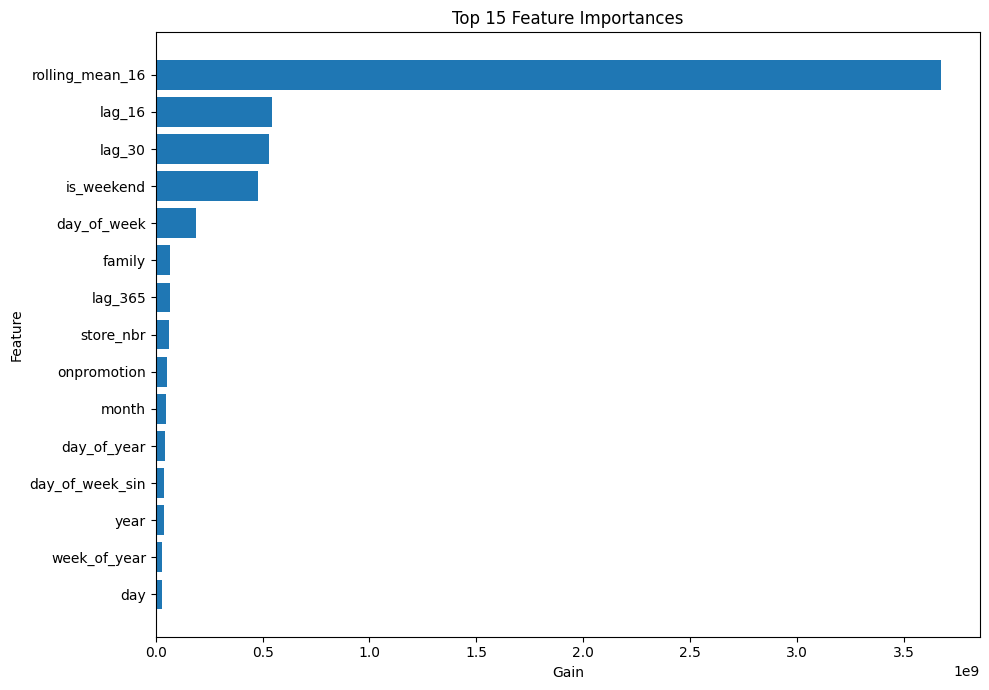

In [58]:
top_features = feature_importance.head(15).sort_values(
    by='importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['feature'],
    top_features['importance']
)

plt.xlabel('Gain')
plt.ylabel('Feature')
plt.title('Top 15 Feature Importances')

plt.tight_layout()
plt.show()

## 12.15 Prediction vs Actual Analysis

Compare the model's predictions with actual sales values to evaluate its forecasting behavior and identify potential prediction errors.

### 12.15.1 Comparing Actual and Predicted Sales

Visualize actual sales against predicted sales using a sample of validation observations to assess how closely the model's predictions follow the actual values.

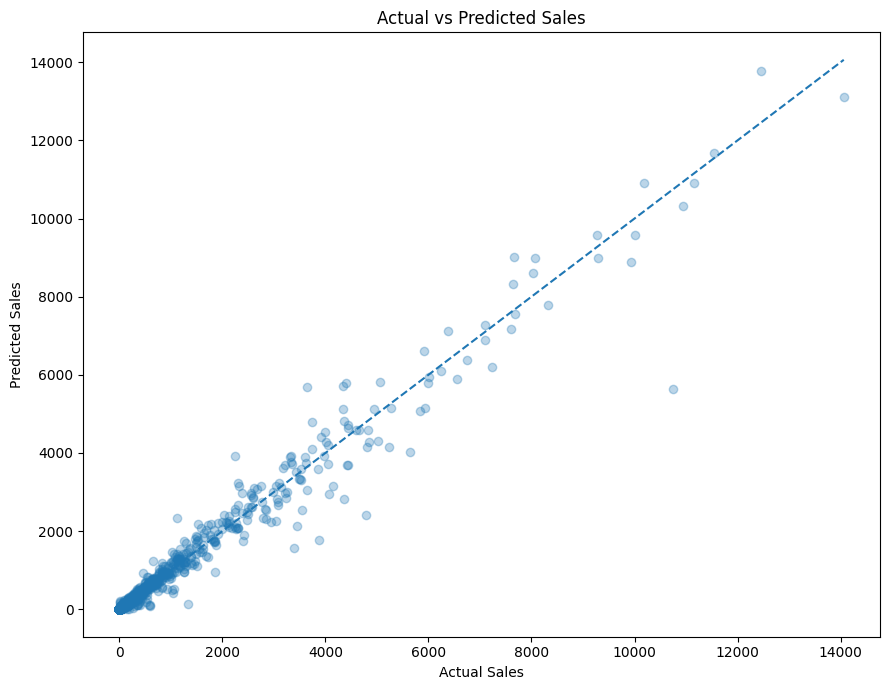

In [59]:
# Create a comparison DataFrame
comparison = pd.DataFrame({
    'actual': y_valid.values,
    'predicted': valid_predictions
})

# Random sample for visualization
sample_comparison = comparison.sample(
    n=2000,
    random_state=42
)

plt.figure(figsize=(9, 7))

plt.scatter(
    sample_comparison['actual'],
    sample_comparison['predicted'],
    alpha=0.3
)

# Perfect prediction reference line
max_value = max(
    sample_comparison['actual'].max(),
    sample_comparison['predicted'].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle='--'
)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')

plt.tight_layout()
plt.show()

**Key Findings:**

- Predictions are relatively close to actual sales for low and moderate sales values.
- Prediction errors generally become more noticeable as actual sales increase.
- The model exhibits both overprediction and underprediction.
- Some observations with high actual sales are substantially underestimated.
- Prediction variability increases at higher sales levels.

**Conclusion:**

The baseline model captures general sales patterns reasonably well but struggles with high-sales observations. Further error analysis is required to identify the main sources of prediction errors.

### 12.15.2 Calculating Prediction Errors

Calculate prediction errors and absolute errors to quantify the differences between actual and predicted sales values.

In [60]:
# Calculate prediction errors
comparison['error'] = (
    comparison['actual'] - comparison['predicted']
)

comparison['absolute_error'] = comparison['error'].abs()

# Summary statistics
print("Error Statistics:")
print(comparison['error'].describe())

print("\nAbsolute Error Statistics:")
print(comparison['absolute_error'].describe())

Error Statistics:
count    28512.000000
mean        -9.169923
std        226.627359
min      -7884.004883
25%        -13.932762
50%         -0.114528
75%          4.821309
max       5093.211914
Name: error, dtype: float64

Absolute Error Statistics:
count    28512.000000
mean        67.146653
std        216.645376
min          0.000000
25%          1.734814
50%          8.184129
75%         40.608917
max       7884.004883
Name: absolute_error, dtype: float64


**Key Findings:**

- The mean prediction error is -9.17, indicating a slight overall tendency toward overprediction.
- The median prediction error is close to zero, suggesting that typical predictions have relatively little directional bias.
- The mean absolute error is 67.15, while the median absolute error is only 8.18.
- The substantial difference between the mean and median absolute errors indicates the presence of large prediction errors in a limited number of observations.
- The maximum absolute error reaches approximately 7,884, highlighting significant prediction failures in some cases.

**Conclusion:**

The baseline model performs relatively well on typical observations but is affected by a number of large prediction errors. Further investigation is needed to identify the stores, product families, and dates associated with these errors.

### 12.15.3 Inspecting the Largest Prediction Errors

Identify the observations with the largest absolute prediction errors and examine their associated dates, stores, and product families to understand where the model struggles most.

In [61]:
# Build a detailed error analysis DataFrame
error_analysis = valid_data[
    ['date', 'store_nbr', 'family', 'onpromotion']
].copy()

error_analysis['actual'] = y_valid.values
error_analysis['predicted'] = valid_predictions
error_analysis['error'] = comparison['error'].values
error_analysis['absolute_error'] = comparison['absolute_error'].values

# Display the 20 largest prediction errors
largest_errors = error_analysis.sort_values(
    by='absolute_error',
    ascending=False
).head(20)

largest_errors


,date,store_nbr,family,onpromotion,actual,predicted,error,absolute_error
2974533,2017-08-01,2,GROCERY I,52,4287.000,12171.004883,-7884.004883,7884.004883
2994894,2017-08-12,40,GROCERY I,60,10739.000,5645.788086,5093.211914,5093.211914
2994432,2017-08-12,28,GROCERY I,57,9841.523,5111.147461,4730.375539,4730.375539
2977003,2017-08-02,39,CLEANING,19,6263.000,1691.276245,4571.723755,4571.723755
2980629,2017-08-04,40,BEVERAGES,26,8272.000,3745.388672,4526.611328,4526.611328
2996214,2017-08-13,28,GROCERY I,60,11002.664,6574.043945,4428.620055,4428.620055
2998623,2017-08-14,45,GROCERY I,39,9665.000,13883.589844,-4218.589844,4218.589844
2976966,2017-08-02,38,BEVERAGES,25,6925.000,2987.402588,3937.597412,3937.597412
2984688,2017-08-06,54,BEVERAGES,21,8552.000,4647.036621,3904.963379,3904.963379
2992542,2017-08-11,25,BEVERAGES,14,6318.000,2548.858154,3769.141846,3769.141846


### 12.15.4 Error Analysis by Product Family

Analyze prediction errors across product families to identify categories where the model performs poorly relative to their actual sales levels.

In [62]:
family_errors = (
    error_analysis.groupby('family')
    .agg(
        mean_actual=('actual', 'mean'),
        mean_predicted=('predicted', 'mean'),
        MAE=('absolute_error', 'mean'),
        total_observations=('actual', 'count')
    )
    .reset_index()
)

family_errors['MAPE'] = (
    error_analysis.assign(
        percentage_error=lambda x:
        x['absolute_error'] / x['actual'].replace(0, np.nan)
    )
    .groupby('family')['percentage_error']
    .mean()
    .values * 100
)

family_errors.sort_values(
    by='MAPE',
    ascending=False
)

/tmp/ipykernel_16/1503124680.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_analysis.groupby('family')
/tmp/ipykernel_16/1503124680.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('family')['percentage_error']


,family,mean_actual,mean_predicted,MAE,total_observations,MAPE
31,SCHOOL AND OFFICE SUPPLIES,59.947917,28.182051,49.309821,864,296.089138
2,BEAUTY,6.663194,10.378326,5.560780,864,168.627110
1,BABY CARE,0.185185,0.826611,0.882164,864,107.334216
4,BOOKS,0.010417,0.713745,0.709638,864,106.719042
21,LINGERIE,7.773148,8.365036,5.239496,864,92.161436
13,GROCERY II,28.971065,29.552187,11.697783,864,87.039341
22,"LIQUOR,WINE,BEER",97.327546,99.824814,37.402665,864,86.401564
17,HOME APPLIANCES,0.200231,0.673432,0.752399,864,83.210000
14,HARDWARE,1.449074,0.888931,1.316947,864,81.321135
19,LADIESWEAR,10.082176,11.748086,5.159433,864,79.971093


**Key Findings:**

- SCHOOL AND OFFICE SUPPLIES recorded the highest MAPE (296.09%), followed by BEAUTY (168.63%), BABY CARE (107.33%), and BOOKS (106.72%).
- Product families with very low average sales tend to exhibit disproportionately high percentage errors.
- GROCERY I recorded a relatively low MAPE of 12.11%, despite having one of the highest mean absolute errors (522.53).
- BEVERAGES also showed a relatively moderate MAPE of 16.21%, despite its high absolute prediction errors.
- These results demonstrate that absolute and percentage-based error metrics provide different perspectives on model performance.

**Conclusion:**

The model's prediction errors vary considerably across product families. High absolute errors are not necessarily an indication of poor relative performance, particularly for high-volume product families. Conversely, low-volume families may exhibit high percentage errors even when their absolute errors are small.

Further evaluation using RMSLE is necessary to identify the product families that contribute most to the competition metric.

### 12.15.5 RMSLE Analysis by Product Family

Evaluate the model's performance across product families using RMSLE to identify categories that contribute most to forecasting errors under the competition evaluation metric.

In [63]:
family_rmsle = (
    error_analysis.groupby('family')
    .apply(
        lambda x: root_mean_squared_log_error(
            x['actual'],
            x['predicted'].clip(lower=0)
        ),
        include_groups=False
    )
    .reset_index(name='RMSLE')
)

family_rmsle = family_rmsle.sort_values(
    by='RMSLE',
    ascending=False
)

family_rmsle

/tmp/ipykernel_16/362719471.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_analysis.groupby('family')


,family,RMSLE
31,SCHOOL AND OFFICE SUPPLIES,1.008326
2,BEAUTY,0.883904
21,LINGERIE,0.810227
14,HARDWARE,0.743423
6,CELEBRATION,0.732713
23,MAGAZINES,0.700582
0,AUTOMOTIVE,0.694813
13,GROCERY II,0.689951
22,"LIQUOR,WINE,BEER",0.663253
32,SEAFOOD,0.660646


**Key Findings:**

- SCHOOL AND OFFICE SUPPLIES recorded the highest RMSLE (1.0083), indicating the weakest forecasting performance among product families.
- BEAUTY and LINGERIE also exhibited relatively high RMSLE values.
- GROCERY I achieved the lowest RMSLE (0.1628), despite having the highest average sales among the product families.
- DAIRY and BREAD/BAKERY also showed relatively strong forecasting performance.
- Model performance varies considerably across product families, suggesting that different product categories exhibit different forecasting patterns.

**Conclusion:**

The baseline model performs well for some high-volume product families but struggles with certain categories, particularly SCHOOL AND OFFICE SUPPLIES, BEAUTY, and LINGERIE.

These differences suggest that further investigation should focus on category-specific sales patterns and potentially useful features that capture their unique behavior.

### 12.15.6 RMSLE Analysis by Store

Evaluate the model's forecasting performance across different stores to identify locations where prediction errors are consistently higher.

In [64]:
store_rmsle = (
    error_analysis.groupby('store_nbr', observed=True)
    .apply(
        lambda x: root_mean_squared_log_error(
            x['actual'],
            x['predicted'].clip(lower=0)
        ),
        include_groups=False
    )
    .reset_index(name='RMSLE')
)

store_rmsle = store_rmsle.sort_values(
    by='RMSLE',
    ascending=False
)

store_rmsle

,store_nbr,RMSLE
18,19,0.744250
51,52,0.694889
31,32,0.675223
21,22,0.674450
35,36,0.664523
19,20,0.653527
14,15,0.652231
13,14,0.641893
11,12,0.641175
9,10,0.635351


**Key Findings:**

- Store 19 recorded the highest RMSLE (0.7443), indicating the weakest forecasting performance.
- Store 8 achieved the lowest RMSLE (0.4003), showing the strongest forecasting performance.
- Prediction performance varies considerably across stores.
- The differences suggest that individual stores may exhibit distinct sales patterns that are not fully captured by the baseline model.

**Conclusion:**

The baseline model performs differently across store locations, suggesting that store-specific characteristics may influence forecasting accuracy.

Further investigation of store metadata, including store type and cluster, may help explain these differences and guide additional feature engineering.

![](http://)

### 12.15.7 Error Analysis by Store Type

Investigate whether forecasting performance varies across store types by combining validation errors with store metadata.

In [65]:
# Add store metadata to the error analysis
store_error_analysis = error_analysis.merge(
    stores[['store_nbr', 'type', 'cluster']],
    on='store_nbr',
    how='left'
)

# Calculate RMSLE by store type
type_rmsle = (
    store_error_analysis.groupby('type', observed=True)
    .apply(
        lambda x: root_mean_squared_log_error(
            x['actual'],
            x['predicted'].clip(lower=0)
        ),
        include_groups=False
    )
    .reset_index(name='RMSLE')
)

type_rmsle.sort_values(
    by='RMSLE',
    ascending=False
)

,type,RMSLE
2,C,0.614534
4,E,0.590138
1,B,0.551469
0,A,0.509837
3,D,0.507835


**Key Findings:**

- Store Type C recorded the highest RMSLE (0.6145), indicating the weakest forecasting performance.
- Store Type E also exhibited relatively high prediction errors, with an RMSLE of 0.5901.
- Store Types A and D achieved the lowest RMSLE values (0.5098 and 0.5078, respectively).
- Forecasting performance varies across store types, suggesting that store characteristics may contain useful predictive information.

**Conclusion:**

The results indicate that store type is associated with differences in forecasting performance. Incorporating store-related features may help the model capture variations in sales behavior across different store categories. However, further analysis is needed before drawing conclusions about the underlying causes.

### 12.15.8 RMSLE Analysis by Store Cluster

Evaluate forecasting performance across store clusters to investigate whether stores with similar characteristics exhibit comparable prediction errors.

In [66]:
cluster_rmsle = (
    store_error_analysis.groupby('cluster', observed=True)
    .apply(
        lambda x: root_mean_squared_log_error(
            x['actual'],
            x['predicted'].clip(lower=0)
        ),
        include_groups=False
    )
    .reset_index(name='RMSLE')
)

cluster_rmsle.sort_values(
    by='RMSLE',
    ascending=False
)

,cluster,RMSLE
6,7,0.658372
14,15,0.655166
0,1,0.583444
2,3,0.580992
9,10,0.573243
5,6,0.562322
10,11,0.561872
15,16,0.547604
11,12,0.537401
12,13,0.516637


**Key Findings:**

- Cluster 7 recorded the highest RMSLE (0.6584), followed closely by Cluster 15 (0.6552).
- Cluster 8 achieved the lowest RMSLE (0.4377), indicating the strongest forecasting performance.
- Noticeable differences in forecasting performance were observed across store clusters.
- The difference between the highest and lowest cluster RMSLE values suggests that stores belonging to different clusters may exhibit distinct sales patterns.
- Store cluster information may provide useful predictive signals for capturing store-level variations.

**Conclusion:**

The analysis reveals substantial differences in forecasting performance across store clusters. This suggests that cluster-related information may help the model represent variations in store behavior.

Further feature engineering experiments will evaluate whether incorporating store metadata improves validation performance.

### 12.15.9 RMSLE Analysis by Day of Week

Investigate whether forecasting performance varies across weekdays to identify recurring weekly patterns associated with higher prediction errors.

In [67]:
weekday_rmsle = (
    error_analysis.assign(
        day_of_week=lambda x: x['date'].dt.dayofweek
    )
    .groupby('day_of_week', observed=True)
    .apply(
        lambda x: root_mean_squared_log_error(
            x['actual'],
            x['predicted'].clip(lower=0)
        ),
        include_groups=False
    )
    .reset_index(name='RMSLE')
)

weekday_names = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

weekday_rmsle['day_name'] = weekday_rmsle['day_of_week'].map(
    weekday_names
)

weekday_rmsle.sort_values(
    by='RMSLE',
    ascending=False
)

,day_of_week,RMSLE,day_name
6,6,0.596274,Sunday
5,5,0.575260,Saturday
4,4,0.573617,Friday
0,0,0.549984,Monday
2,2,0.533259,Wednesday
1,1,0.526563,Tuesday
3,3,0.520432,Thursday


**Key Findings:**

- Sunday recorded the highest RMSLE (0.5963), indicating the weakest forecasting performance.
- Saturday and Friday also exhibited relatively high RMSLE values.
- Thursday achieved the lowest RMSLE (0.5204), followed by Tuesday and Wednesday.
- Forecasting errors appear to be higher during weekends than on most weekdays.
- These results are consistent with the previously observed differences in average sales across weekdays.

**Conclusion:**

The analysis suggests that the model struggles more with weekend sales patterns, particularly on Sundays.

This indicates a potential opportunity to improve temporal feature engineering and capture weekly sales behavior more effectively. However, further experiments are required to determine whether additional weekday-related features improve validation performance.

## 12.16 Store Metadata Feature Engineering

Incorporate additional store-related information to help the model capture differences in sales behavior across locations.

The store metadata includes store type, city, state, and cluster. These features will be merged into both training and test datasets using the store identifier.

In [68]:
# Select store metadata
store_features = stores[
    ['store_nbr', 'city', 'state', 'type', 'cluster']
].copy()

# Merge metadata into training and test datasets
train = train.merge(
    store_features,
    on='store_nbr',
    how='left'
)

test = test.merge(
    store_features,
    on='store_nbr',
    how='left'
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nMissing values in store features:")
print(train[['city', 'state', 'type', 'cluster']].isnull().sum())
print(test[['city', 'state', 'type', 'cluster']].isnull().sum())

Train shape: (3000888, 27)
Test shape: (28512, 22)

Missing values in store features:
city       0
state      0
type       0
cluster    0
dtype: int64
city       0
state      0
type       0
cluster    0
dtype: int64


In [69]:
categorical_features = [
    'family',
    'store_nbr',
    'city',
    'state',
    'type',
    'cluster'
]

for col in categorical_features:
    categories = pd.concat([train[col], test[col]]).unique()

    train[col] = pd.Categorical(train[col], categories=categories)
    test[col] = pd.Categorical(test[col], categories=categories)

In [70]:
for col in categorical_features:
    print(
        col,
        train[col].dtype,
        test[col].dtype,
        train[col].cat.categories.equals(test[col].cat.categories)
    )

family category category True
store_nbr category category True
city category category True
state category category True
type category category True
cluster category category True


## 12.17 Improved Model Training

### 12.17.1 Prepare Training and Validation Sets

In [71]:
validation_start = '2017-07-31'

train_data = train[train['date'] < validation_start].copy()
valid_data = train[train['date'] >= validation_start].copy()

In [72]:
target = 'sales'

drop_columns = ['id', 'date', target]

features = [
    col for col in train.columns
    if col not in drop_columns
]

X_train = train_data[features]
y_train = train_data[target]

X_valid = valid_data[features]
y_valid = valid_data[target]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("Number of features:", len(features))

X_train: (2972376, 24)
X_valid: (28512, 24)
Number of features: 24


### 12.17.2 Train Improved XGBoost Model

In [73]:
improved_model = XGBRegressor(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    tree_method='hist',
    enable_categorical=True,
    n_jobs=-1,
    random_state=42
)

improved_model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=50
)

[0]	validation_0-rmse:1134.19727
[50]	validation_0-rmse:255.78031
[100]	validation_0-rmse:250.36595
[150]	validation_0-rmse:239.61916
[199]	validation_0-rmse:235.27544


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=-1, num_parallel_tree=None, ...)

In [74]:
improved_predictions = improved_model.predict(X_valid)

improved_rmsle = root_mean_squared_log_error(
    y_valid,
    improved_predictions.clip(min=0)
)

print(f"Improved Model RMSLE: {improved_rmsle:.5f}")
print(f"Baseline RMSLE: 0.55231")
print(f"Difference: {improved_rmsle - 0.55231:.5f}")

Improved Model RMSLE: 0.53499
Baseline RMSLE: 0.55231
Difference: -0.01732


### Key Findings

- The Improved XGBoost model achieved a Validation RMSLE of 0.53499.
- The Baseline model achieved a Validation RMSLE of 0.55231.
- The Improved model reduced RMSLE by 0.01732 (approximately 3.14%).
- The result indicates better predictive performance on the current validation period.
- Further validation is required before concluding that the improvement will generalize to unseen data.

In [75]:
print("Baseline feature count:", len(X_train.columns))
print("Current feature count:", len(features))

print("\nCurrent features:")
print(features)

Baseline feature count: 24
Current feature count: 24

Current features:
['store_nbr', 'family', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'week_of_year', 'is_weekend', 'quarter', 'month_sin', 'month_cos', 'day_of_week_sin', 'day_of_week_cos', 'lag_16', 'lag_30', 'lag_365', 'rolling_mean_16', 'family_code', 'city', 'state', 'type', 'cluster']


In [76]:
baseline_features = [
    'store_nbr',
    'family',
    'onpromotion',
    'year',
    'month',
    'day',
    'day_of_week',
    'day_of_year',
    'week_of_year',
    'is_weekend',
    'quarter',
    'month_sin',
    'month_cos',
    'day_of_week_sin',
    'day_of_week_cos',
    'lag_16',
    'lag_30',
    'lag_365',
    'rolling_mean_16'
]

metadata_features = [
    'city',
    'state',
    'type',
    'cluster'
]

improved_features = baseline_features + metadata_features

print("Baseline features:", len(baseline_features))
print("Improved features:", len(improved_features))

Baseline features: 19
Improved features: 23


### 12.17.5 Rebuild the Improved Model Dataset

In [77]:
X_train = train_data[improved_features]
y_train = train_data['sales']

X_valid = valid_data[improved_features]
y_valid = valid_data['sales']

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

X_train: (2972376, 23)
X_valid: (28512, 23)


### 12.17.6 Retrain Controlled Improved Model

In [78]:
controlled_model = XGBRegressor(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    tree_method='hist',
    enable_categorical=True,
    n_jobs=-1,
    random_state=42
)

controlled_model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=50
)

[0]	validation_0-rmse:1131.54236
[50]	validation_0-rmse:252.67368
[100]	validation_0-rmse:240.23234
[150]	validation_0-rmse:231.94304
[199]	validation_0-rmse:230.78328


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=-1, num_parallel_tree=None, ...)

In [79]:
controlled_predictions = controlled_model.predict(X_valid)

controlled_rmsle = root_mean_squared_log_error(
    y_valid,
    controlled_predictions.clip(min=0)
)

print(f"Controlled Improved RMSLE: {controlled_rmsle:.5f}")
print(f"Baseline RMSLE: 0.55231")
print(f"Difference: {controlled_rmsle - 0.55231:.5f}")

Controlled Improved RMSLE: 0.60339
Baseline RMSLE: 0.55231
Difference: 0.05108


In [80]:
print("Baseline model exists:", 'model' in globals())
print("Controlled model exists:", 'controlled_model' in globals())

print("Baseline features:", len(baseline_features))
print("Improved features:", len(improved_features))

Baseline model exists: True
Controlled model exists: True
Baseline features: 19
Improved features: 23


### 12.17.8 Individual Store Metadata Experiments

In [81]:
metadata_features = ['city', 'state', 'type', 'cluster']

ablation_results = []

for feature in metadata_features:

    current_features = baseline_features + [feature]

    X_train_exp = train_data[current_features]
    X_valid_exp = valid_data[current_features]

    experiment_model = XGBRegressor(
        n_estimators=200,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        tree_method='hist',
        enable_categorical=True,
        n_jobs=-1,
        random_state=42
    )

    experiment_model.fit(
        X_train_exp,
        y_train,
        eval_set=[(X_valid_exp, y_valid)],
        verbose=False
    )

    predictions = experiment_model.predict(X_valid_exp)

    score = root_mean_squared_log_error(
        y_valid,
        predictions.clip(min=0)
    )

    ablation_results.append({
        'Added Feature': feature,
        'Number of Features': len(current_features),
        'Validation RMSLE': score
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df = ablation_df.sort_values(
    'Validation RMSLE'
).reset_index(drop=True)

display(ablation_df)


,Added Feature,Number of Features,Validation RMSLE
0,state,20,0.516741
1,cluster,20,0.556190
2,type,20,0.558932
3,city,20,0.571262


### 12.17.9 Testing Feature Combinations

### Testing Store Metadata Combinations

After identifying `state` as the most useful individual store metadata feature, additional experiments are conducted to evaluate whether combining it with other metadata features can further improve model performance.

Each experiment retains the baseline features and adds `state` together with one additional metadata feature.

In [82]:
additional_features = ['city', 'type', 'cluster']

combination_results = []

for feature in additional_features:

    current_features = baseline_features + ['state', feature]

    X_train_exp = train_data[current_features]
    X_valid_exp = valid_data[current_features]

    experiment_model = XGBRegressor(
        n_estimators=200,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        tree_method='hist',
        enable_categorical=True,
        n_jobs=-1,
        random_state=42
    )

    experiment_model.fit(
        X_train_exp,
        y_train,
        eval_set=[(X_valid_exp, y_valid)],
        verbose=False
    )

    predictions = experiment_model.predict(X_valid_exp)

    score = root_mean_squared_log_error(
        y_valid,
        predictions.clip(min=0)
    )

    combination_results.append({
        'Added Features': f'state + {feature}',
        'Number of Features': len(current_features),
        'Validation RMSLE': score
    })

combination_df = pd.DataFrame(combination_results)

combination_df = combination_df.sort_values(
    'Validation RMSLE'
).reset_index(drop=True)

display(combination_df)

,Added Features,Number of Features,Validation RMSLE
0,state + cluster,21,0.545156
1,state + city,21,0.552771
2,state + type,21,0.565669


### Best Feature Selection

Based on individual feature experiments and combination testing, `state` was identified as the most effective store metadata feature.

Adding `state` to the baseline features reduced the validation RMSLE from 0.55231 to 0.516741.

Additional experiments showed that combining `state` with `city`, `type`, or `cluster` did not provide further improvements.

Therefore, the selected feature set consists of the 19 baseline features and the `state` feature.

In [83]:
best_features = baseline_features + ['state']

X_train_best = train_data[best_features]
X_valid_best = valid_data[best_features]

print("Training shape:", X_train_best.shape)
print("Validation shape:", X_valid_best.shape)
print("Number of features:", len(best_features))

Training shape: (2972376, 20)
Validation shape: (28512, 20)
Number of features: 20
